# Поиск похожих пользователей: точные соседи, ANN и влияние `log1p`

В этом notebook строится практический пайплайн поиска похожих пользователей по агрегированным транзакционным признакам из файла `data/user_features_data1.csv`.

Что здесь будет сделано:

- загрузка и аудит реального CSV;
- аккуратная подготовка признаков;
- построение двух вариантов препроцессинга:
  - без `log1p`;
  - с выборочным `log1p` для тяжёлых счётчиков и intensity-признаков;
- точный baseline на воспроизводимой выборке;
- сравнение `cosine`, `euclidean` и `manhattan` по качеству, overlap и расстояниям;
- расчёт ошибки метрик относительно `euclidean` как условной эталонной метрики;
- ANN-поиск для практического top-200 retrieval;
- итоговая функция `get_200_nearest(...)`.

Под `exact` здесь понимается точный перебор кандидатов в выбранном корпусе.  
Под `ANN` — приближённый индекс, который ускоряет поиск ближайших соседей и затем при необходимости допускает небольшую потерю точности.

Важный акцент этого notebook: мы отдельно смотрим, как меняется геометрия пространства **без `log1p` и с `log1p`**, и почему после `log1p` метрики часто начинают вести себя заметно ближе друг к другу.


## Импорты и настройка окружения

Подключаем библиотеки для анализа данных, поиска соседей и визуализаций.  
Отдельно фиксируем `seed`, настраиваем `matplotlib` для корректного отображения кириллицы и включаем параметры, которые делают выводы более читаемыми.


In [1]:
from __future__ import annotations

import gc
import importlib
import warnings
from pathlib import Path
from time import perf_counter
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")

SEED = 42
TOP_K = 200
SCHEMA_SAMPLE_ROWS = 2_000

np.random.seed(SEED)

DATA_PATH = Path("data/user_features_data1.csv")
DOCS_PATH = Path("docs_users.md")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

print(f"Файл с признаками: {DATA_PATH.resolve()}")
print(f"CSV найден: {DATA_PATH.exists()}")
print(f"Документация найдена: {DOCS_PATH.exists()}")


Файл с признаками: C:\PROD2026\ThirdStageCommand\data\user_features_data1.csv
CSV найден: True
Документация найдена: True


## Загрузка схемы CSV и первичный аудит колонок

Сначала читаем небольшой фрагмент файла, чтобы:

- получить реальный полный список колонок;
- отделить `id`, datetime-поля, числовые признаки и строковые категории;
- подготовить `dtype`-схему для более аккуратной полной загрузки большого CSV.

Такой двухшаговый подход полезен, когда файл большой, а память и время хочется тратить осмысленно.


In [2]:
def looks_like_iso_datetime(series: pd.Series) -> bool:
    sample = series.dropna().astype("string").head(200)
    if sample.empty:
        return False
    has_iso_pattern = sample.str.contains(r"\d{4}-\d{2}-\d{2}", regex=True).mean()
    parsed_share = pd.to_datetime(sample, errors="coerce").notna().mean()
    return has_iso_pattern >= 0.8 and parsed_share >= 0.8


def inspect_schema(path: Path, sample_rows: int = 2_000) -> dict:
    sample_df = pd.read_csv(path, nrows=sample_rows)

    columns = sample_df.columns.tolist()
    id_cols: list[str] = []
    datetime_cols: list[str] = []
    int_like_cols: list[str] = []
    float_like_cols: list[str] = []
    object_like_cols: list[str] = []

    for col in columns:
        if col == "party_rk":
            id_cols.append(col)
            continue

        series = sample_df[col]
        if col.endswith("_dttm") or looks_like_iso_datetime(series):
            datetime_cols.append(col)
            continue

        numeric = pd.to_numeric(series, errors="coerce")
        numeric_share = numeric.notna().mean()
        if numeric_share >= 0.98:
            finite = numeric.dropna().to_numpy(dtype=float)
            if finite.size and np.all(np.isclose(finite, np.round(finite))):
                int_like_cols.append(col)
            else:
                float_like_cols.append(col)
        else:
            object_like_cols.append(col)

    return {
        "columns": columns,
        "id_cols": id_cols,
        "datetime_cols": datetime_cols,
        "int_like_cols": int_like_cols,
        "float_like_cols": float_like_cols,
        "object_like_cols": object_like_cols,
        "sample_df": sample_df,
    }


schema = inspect_schema(DATA_PATH, sample_rows=SCHEMA_SAMPLE_ROWS)

schema_summary = pd.DataFrame(
    {
        "Группа": [
            "Идентификатор",
            "Datetime-поля",
            "Целочисленные признаки",
            "Вещественные признаки",
            "Строковые / категориальные признаки",
            "Всего колонок",
        ],
        "Количество": [
            len(schema["id_cols"]),
            len(schema["datetime_cols"]),
            len(schema["int_like_cols"]),
            len(schema["float_like_cols"]),
            len(schema["object_like_cols"]),
            len(schema["columns"]),
        ],
    }
)

display(schema_summary)
print("Полный список колонок из CSV:")
for col in schema["columns"]:
    print(" -", col)


,Группа,Количество
0,Идентификатор,1
1,Datetime-поля,2
2,Целочисленные признаки,14
3,Вещественные признаки,79
4,Строковые / категориальные признаки,2
5,Всего колонок,98


Полный список колонок из CSV:
 - party_rk
 - txn_cnt
 - unique_transaction_cnt
 - active_days_cnt
 - active_months_cnt
 - active_weeks_cnt
 - first_txn_dttm
 - last_txn_dttm
 - activity_span_days
 - avg_txn_per_active_day
 - avg_txn_per_month_active
 - avg_txn_per_week_active
 - dominant_hour
 - dominant_weekday_num
 - share_weekend_txn
 - share_weekday_txn
 - share_night_txn
 - share_morning_txn
 - share_afternoon_txn
 - share_evening_txn
 - dominant_daypart
 - max_txn_in_one_day
 - median_txn_per_active_day
 - unique_category_cnt
 - top_category_txn_share
 - category_entropy
 - cat_share_супермаркеты
 - cat_share_фаст_фуд
 - cat_share_транспорт
 - cat_share_разные_товары
 - cat_share_топливо
 - cat_share_рестораны
 - cat_share_аптеки
 - cat_share_дом_ремонт
 - cat_share_развлечения
 - cat_share_сервисные_услуги
 - cat_share_автоуслуги
 - cat_share_связь_телеком
 - cat_share_одежда_обувь
 - cat_share_красота
 - cat_share_медицинские_услуги
 - cat_share_госсборы
 - cat_share_аренда_авт

## Полная загрузка датасета

Теперь загружаем весь CSV уже с осмысленной схемой типов:

- `party_rk` оставляем строковым идентификатором;
- datetime-колонки парсим как даты;
- строковые категориальные поля читаем как `category`;
- числа, где возможно, downcast-им до `int32` и `float32`.

После этого сразу смотрим размер таблицы, первые строки, распределение типов и доли пропусков.


In [4]:
dtype_map: dict[str, str] = {"party_rk": "string"}
for col in schema["int_like_cols"]:
    dtype_map[col] = "int32"
for col in schema["float_like_cols"]:
    dtype_map[col] = "float32"
for col in schema["object_like_cols"]:
    dtype_map[col] = "category"

load_start = perf_counter()
df = pd.read_csv(
    DATA_PATH,
    parse_dates=schema["datetime_cols"],
    low_memory=False,
)
load_seconds = perf_counter() - load_start

print(f"Полная загрузка завершена за {load_seconds:,.2f} сек.")
print(f"Размер таблицы: {df.shape[0]:,} строк x {df.shape[1]:,} колонок")

display(df.head())

dtype_overview = (
    df.dtypes.astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="Количество колонок")
)
display(dtype_overview)

missing_overview = (
    df.isna()
    .mean()
    .sort_values(ascending=False)
    .rename("Доля пропусков")
    .to_frame()
)
display(missing_overview.head(15))


Полная загрузка завершена за 39.28 сек.
Размер таблицы: 1,217,027 строк x 98 колонок


,party_rk,txn_cnt,unique_transaction_cnt,active_days_cnt,active_months_cnt,active_weeks_cnt,first_txn_dttm,last_txn_dttm,activity_span_days,avg_txn_per_active_day,avg_txn_per_month_active,avg_txn_per_week_active,dominant_hour,dominant_weekday_num,share_weekend_txn,share_weekday_txn,share_night_txn,share_morning_txn,share_afternoon_txn,share_evening_txn,dominant_daypart,max_txn_in_one_day,median_txn_per_active_day,unique_category_cnt,top_category_txn_share,category_entropy,cat_share_супермаркеты,cat_share_фаст_фуд,cat_share_транспорт,cat_share_разные_товары,cat_share_топливо,cat_share_рестораны,cat_share_аптеки,cat_share_дом_ремонт,cat_share_развлечения,cat_share_сервисные_услуги,cat_share_автоуслуги,cat_share_связь_телеком,cat_share_одежда_обувь,cat_share_красота,cat_share_медицинские_услуги,cat_share_госсборы,cat_share_аренда_авто,cat_share_частные_услуги,cat_share_нко,cat_share_финансовые_услуги,cat_share_цветы,cat_share_книги,cat_share_животные,cat_share_образование,cat_share_кино,cat_share_турагентства,cat_share_ж_д_билеты,cat_share_авиабилеты,cat_share_спорттовары,cat_share_unknown,cat_share_other,unique_mcc_cnt,top_mcc_txn_share,mcc_entropy,mcc_share_5411,mcc_share_5814,mcc_share_5499,mcc_share_3990,mcc_share_4131,mcc_share_5912,mcc_share_5541,mcc_share_5921,mcc_share_5812,mcc_share_4111,mcc_share_5300,mcc_share_4121,mcc_share_5200,mcc_share_7995,mcc_share_5331,mcc_share_5993,mcc_share_7542,mcc_share_5964,mcc_share_4900,mcc_share_5816,mcc_share_3991,mcc_share_5815,mcc_share_5311,mcc_share_5462,mcc_share_7512,mcc_share_4814,mcc_share_4816,mcc_share_5399,mcc_share_5977,mcc_share_5533,mcc_share_unknown,mcc_share_other,unique_merchant_cnt,top_merchant_txn_share,dominant_weekday,merchant_diversity_ratio,category_diversity_ratio,mcc_diversity_ratio
0,07e95d24bb488b49697420c27d035110259f37ccb1c3fddb01c8b6cd8ae4ee13,2,2,1,1,1,2025-02-03 14:17:04,2025-02-03 14:28:39,0,2.000000,2.0,2.0,14,1,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,afternoon,2,2.0,1,1.000000,-0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,1,1.000000,-0.000000,1.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,2,0.500000,Monday,1.000000,0.500000,0.500000
1,cb450aa7466b337776f0f76debb5a485da9afeb7f49ec5d35481d65b8b822e31,62,62,21,1,5,2025-02-01 16:32:20,2025-02-28 22:11:01,27,2.952381,62.0,12.4,19,4,0.274194,0.725806,0.000000,0.161290,0.435484,0.403226,afternoon,9,2.0,14,0.161290,2.386007,0.161290,0.161290,0.145161,0.048387,0.080645,0.112903,0.032258,0.0,0.000000,0.0,0.032258,0.016129,0.064516,0.0,0.016129,0.064516,0.0,0.016129,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.048387,0.0,21,0.161290,2.649669,0.145161,0.161290,0.0,0.016129,0.0,0.032258,0.064516,0.0,0.112903,0.129032,0.016129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.016129,0.000000,0.0,0.0,0.0,0.016129,0.0,0.032258,0.0,0.032258,0.0,0.225806,36,0.129032,Thursday,0.580645,0.225806,0.338710
2,826ea969a9b6ddc9de5c48bc0cea7e3fae27a340c95dcc329c079caf987c593e,4,4,3,1,2,2025-02-11 06:53:44,2025-02-27 07:11:47,16,1.333333,4.0,2.0,6,2,0.000000,1.000000,0.000000,0.750000,0.250000,0.000000,morning,2,1.0,1,1.000000,-0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,1,1.000000,-0.000000,0.000000,0.000000,1.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,2,0.750000,Tuesday,0.500000,0.250000,0.250000
3,ac290da8c2f1d18d64c8f0d2c0c8a237c1dc21b97dc42f879eb0483f5364fa5c,3,3,3,1,3,2025-02-02 14:03:38,2025-02-28 05:58

,dtype,Количество колонок
0,float64,81
1,int64,12
2,object,3
3,datetime64[ns],2


,Доля пропусков
party_rk,0.0
txn_cnt,0.0
unique_transaction_cnt,0.0
active_days_cnt,0.0
active_months_cnt,0.0
active_weeks_cnt,0.0
first_txn_dttm,0.0
last_txn_dttm,0.0
activity_span_days,0.0
avg_txn_per_active_day,0.0


## Аудит подозрительных полей и групп признаков

Для поиска похожих пользователей важно отдельно проверить:

- что действительно является идентификатором;
- какие поля нужно преобразовать как datetime;
- какие строковые поля требуют кодировки;
- сколько у нас признаков семейства `cat_share_*`, `mcc_share_*`, `entropy`, `ratio`.

Это влияет и на подготовку признаков, и на то, к каким колонкам имеет смысл применять `log1p`.


In [5]:
audit_groups = pd.DataFrame(
    {
        "Группа": [
            "ID",
            "Datetime",
            "Int-like",
            "Float-like",
            "Object-like",
        ],
        "Колонки": [
            ", ".join(schema["id_cols"]),
            ", ".join(schema["datetime_cols"]),
            ", ".join(schema["int_like_cols"][:12]) + (" ..." if len(schema["int_like_cols"]) > 12 else ""),
            ", ".join(schema["float_like_cols"][:12]) + (" ..." if len(schema["float_like_cols"]) > 12 else ""),
            ", ".join(schema["object_like_cols"]),
        ],
    }
)
display(audit_groups)

suspicious_snapshot = {
    "dominant_daypart": sorted(df["dominant_daypart"].astype("string").dropna().unique().tolist()),
    "dominant_weekday": sorted(df["dominant_weekday"].astype("string").dropna().unique().tolist()),
    "dominant_weekday_num": sorted(df["dominant_weekday_num"].dropna().unique().tolist()),
}

for col_name, values in suspicious_snapshot.items():
    print(f"{col_name}: {values}")

prefix_group_counts = pd.DataFrame(
    {
        "Группа признаков": [
            "cat_share_*",
            "mcc_share_*",
            "Признаки с entropy",
            "Признаки с diversity_ratio",
        ],
        "Количество колонок": [
            sum(col.startswith("cat_share_") for col in df.columns),
            sum(col.startswith("mcc_share_") for col in df.columns),
            sum("entropy" in col for col in df.columns),
            sum(col.endswith("diversity_ratio") for col in df.columns),
        ],
    }
)
display(prefix_group_counts)


,Группа,Колонки
0,ID,party_rk
1,Datetime,"first_txn_dttm, last_txn_dttm"
2,Int-like,"txn_cnt, unique_transaction_cnt, active_days_cnt, active_months_cnt, active_weeks_cnt, activity_span_days, avg_txn_p..."
3,Float-like,"avg_txn_per_active_day, avg_txn_per_week_active, share_weekend_txn, share_weekday_txn, share_night_txn, share_mornin..."
4,Object-like,"dominant_daypart, dominant_weekday"


dominant_daypart: ['afternoon', 'evening', 'morning', 'night']
dominant_weekday: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
dominant_weekday_num: [1, 2, 3, 4, 5, 6, 7]


,Группа признаков,Количество колонок
0,cat_share_*,31
1,mcc_share_*,32
2,Признаки с entropy,2
3,Признаки с diversity_ratio,3


## Подготовка признаков для поиска похожих пользователей

Здесь важно не просто «скормить всё числовое в модель», а принять несколько осмысленных решений:

1. `party_rk` исключается из матрицы признаков.
2. `first_txn_dttm` и `last_txn_dttm` превращаются в числовые признаки давности относительно максимальной даты в датасете.
3. `dominant_hour` и `dominant_weekday_num` кодируются циклически через `sin/cos`, чтобы 23:00 и 00:00, а также соседние дни недели не считались искусственно далёкими.
4. `dominant_daypart` кодируется через one-hot.
5. Пропуски обрабатываются явно, даже если текущая выгрузка почти полностью заполнена.


In [6]:
PROFILE_COLUMNS = [
    "txn_cnt",
    "active_days_cnt",
    "active_weeks_cnt",
    "active_months_cnt",
    "activity_span_days",
    "avg_txn_per_active_day",
    "avg_txn_per_month_active",
    "avg_txn_per_week_active",
    "share_weekend_txn",
    "share_weekday_txn",
    "share_night_txn",
    "share_morning_txn",
    "share_afternoon_txn",
    "share_evening_txn",
    "unique_category_cnt",
    "top_category_txn_share",
    "category_entropy",
    "unique_mcc_cnt",
    "top_mcc_txn_share",
    "mcc_entropy",
    "unique_merchant_cnt",
    "top_merchant_txn_share",
    "merchant_diversity_ratio",
    "category_diversity_ratio",
    "mcc_diversity_ratio",
    "dominant_hour",
    "dominant_weekday",
    "dominant_daypart",
]


def prepare_feature_table(frame: pd.DataFrame) -> tuple[pd.DataFrame, list[str], dict]:
    work = frame.copy()
    work["first_txn_dttm"] = pd.to_datetime(work["first_txn_dttm"], errors="coerce")
    work["last_txn_dttm"] = pd.to_datetime(work["last_txn_dttm"], errors="coerce")

    max_last_txn = work["last_txn_dttm"].max()
    work["days_since_first_txn"] = (
        (max_last_txn - work["first_txn_dttm"]).dt.total_seconds() / 86_400
    ).astype("float32")
    work["days_since_last_txn"] = (
        (max_last_txn - work["last_txn_dttm"]).dt.total_seconds() / 86_400
    ).astype("float32")

    weekday_base = int(work["dominant_weekday_num"].min())
    weekday_zero_based = (work["dominant_weekday_num"].astype("int16") - weekday_base) % 7

    hour_angle = 2 * np.pi * work["dominant_hour"].astype("float32") / 24.0
    weekday_angle = 2 * np.pi * weekday_zero_based.astype("float32") / 7.0

    work["dominant_hour_sin"] = np.sin(hour_angle).astype("float32")
    work["dominant_hour_cos"] = np.cos(hour_angle).astype("float32")
    work["dominant_weekday_sin"] = np.sin(weekday_angle).astype("float32")
    work["dominant_weekday_cos"] = np.cos(weekday_angle).astype("float32")

    work["dominant_daypart"] = work["dominant_daypart"].astype("string").fillna("unknown")
    work = pd.get_dummies(
        work,
        columns=["dominant_daypart"],
        prefix="dominant_daypart",
        dtype=np.int8,
    )

    numeric_cols = work.select_dtypes(include=[np.number, "bool"]).columns.tolist()
    work[numeric_cols] = work[numeric_cols].apply(lambda col: col.fillna(col.median()))

    residual_non_numeric = [
        col
        for col in work.columns
        if col != "party_rk" and not pd.api.types.is_numeric_dtype(work[col])
    ]
    for col in residual_non_numeric:
        work[col] = work[col].astype("string").fillna("unknown")

    drop_cols = [
        "first_txn_dttm",
        "last_txn_dttm",
        "dominant_weekday",
        "dominant_hour",
        "dominant_weekday_num",
    ]

    prepared = work.drop(columns=drop_cols)
    feature_cols = [col for col in prepared.columns if col != "party_rk"]

    non_numeric_features = [
        col
        for col in feature_cols
        if not pd.api.types.is_numeric_dtype(prepared[col])
    ]
    if non_numeric_features:
        raise ValueError(f"В матрице остались нечисловые признаки: {non_numeric_features}")

    prepared[feature_cols] = prepared[feature_cols].astype("float32")
    prepared[feature_cols] = prepared[feature_cols].fillna(
        prepared[feature_cols].median(numeric_only=True)
    )

    report = {
        "Пользователей": int(prepared.shape[0]),
        "Итоговых признаков": int(len(feature_cols)),
        "Добавлено datetime-признаков": 2,
        "Добавлено циклических признаков": 4,
        "Добавлено one-hot по dominant_daypart": int(
            sum(col.startswith("dominant_daypart_") for col in feature_cols)
        ),
        "Удалено сырьевых datetime-колонок": 2,
        "Удалено сырьевых категориальных/циклических колонок": 3,
    }
    return prepared, feature_cols, report


prepared_df, feature_cols, prep_report = prepare_feature_table(df)

profile_view = df[["party_rk"] + [col for col in PROFILE_COLUMNS if col in df.columns]].copy()
profile_view["days_since_first_txn"] = prepared_df["days_since_first_txn"].astype("float32")
profile_view["days_since_last_txn"] = prepared_df["days_since_last_txn"].astype("float32")
profile_view = profile_view.set_index("party_rk")

display(pd.Series(prep_report, name="Значение").to_frame())
print("Первые 20 итоговых признаков:")
print(feature_cols[:20])
print("...")
print("Последние 20 итоговых признаков:")
print(feature_cols[-20:])


,Значение
Пользователей,1217027
Итоговых признаков,101
Добавлено datetime-признаков,2
Добавлено циклических признаков,4
Добавлено one-hot по dominant_daypart,4
Удалено сырьевых datetime-колонок,2
Удалено сырьевых категориальных/циклических колонок,3


Первые 20 итоговых признаков:
['txn_cnt', 'unique_transaction_cnt', 'active_days_cnt', 'active_months_cnt', 'active_weeks_cnt', 'activity_span_days', 'avg_txn_per_active_day', 'avg_txn_per_month_active', 'avg_txn_per_week_active', 'share_weekend_txn', 'share_weekday_txn', 'share_night_txn', 'share_morning_txn', 'share_afternoon_txn', 'share_evening_txn', 'max_txn_in_one_day', 'median_txn_per_active_day', 'unique_category_cnt', 'top_category_txn_share', 'category_entropy']
...
Последние 20 итоговых признаков:
['mcc_share_5399', 'mcc_share_5977', 'mcc_share_5533', 'mcc_share_unknown', 'mcc_share_other', 'unique_merchant_cnt', 'top_merchant_txn_share', 'merchant_diversity_ratio', 'category_diversity_ratio', 'mcc_diversity_ratio', 'days_since_first_txn', 'days_since_last_txn', 'dominant_hour_sin', 'dominant_hour_cos', 'dominant_weekday_sin', 'dominant_weekday_cos', 'dominant_daypart_afternoon', 'dominant_daypart_evening', 'dominant_daypart_morning', 'dominant_daypart_night']


## Краткий словарь признаков

Ниже — аккуратная интерпретация групп признаков. Она опирается на локальный файл `docs_users.md` и на смысл названий колонок.

- **Интенсивность активности**: `txn_cnt`, `active_days_cnt`, `active_weeks_cnt`, `active_months_cnt`, `avg_txn_per_*`, `max_txn_in_one_day`, `median_txn_per_active_day`.
- **Временной профиль**: `share_night_txn`, `share_morning_txn`, `share_afternoon_txn`, `share_evening_txn`, `share_weekend_txn`, `share_weekday_txn`, а также производные `days_since_*`.
- **Категорийный профиль**: `unique_category_cnt`, `top_category_txn_share`, `category_entropy`, `cat_share_*`.
- **MCC-профиль**: `unique_mcc_cnt`, `top_mcc_txn_share`, `mcc_entropy`, `mcc_share_*`.
- **Разнообразие и концентрация**: `unique_merchant_cnt`, `top_merchant_txn_share`, `merchant_diversity_ratio`, `category_diversity_ratio`, `mcc_diversity_ratio`.

Если точное бизнес-описание признака не раскрыто в документации, здесь не делаются более сильные предположения, чем позволяют название и структура данных.


## Стратегия `log1p`

Основной scaler в notebook остаётся **`RobustScaler`**, как и требовалось.  
Но теперь поверх него мы отдельно сравниваем два сценария:

- **без `log1p`**: только подготовка признаков и затем `RobustScaler`;
- **с выборочным `log1p`**: сначала `log1p` для тяжёлых счётчиков и intensity-признаков, затем `RobustScaler`.

Важно: `log1p` не применяется ко всей матрице подряд. Мы **не трогаем**:

- доли и распределения `share_*`;
- `entropy`-признаки;
- `*_ratio`;
- one-hot признаки `dominant_daypart_*`;
- циклические `sin/cos` признаки.

Это сделано потому, что `log1p` полезен именно там, где есть тяжёлые правые хвосты и сильный масштабный перекос, а не на уже ограниченных признаках вида `0..1`.


In [7]:
def select_log1p_columns(feature_frame: pd.DataFrame, feature_cols: list[str]) -> list[str]:
    blocked_prefixes = ("share_", "cat_share_", "mcc_share_", "dominant_daypart_")
    blocked_suffixes = ("_ratio", "_sin", "_cos")
    blocked_substrings = ("entropy",)

    selected: list[str] = []
    for col in feature_cols:
        if col.startswith(blocked_prefixes):
            continue
        if col.endswith(blocked_suffixes):
            continue
        if any(token in col for token in blocked_substrings):
            continue

        name_based_match = (
            ("_cnt" in col)
            or col.startswith("avg_txn_per_")
            or col.startswith("days_since_")
            or col == "activity_span_days"
            or col == "max_txn_in_one_day"
            or col == "median_txn_per_active_day"
        )
        if not name_based_match:
            continue

        series = feature_frame[col]
        if (series < 0).any():
            continue
        selected.append(col)

    return selected


log1p_columns = select_log1p_columns(prepared_df, feature_cols)
log1p_column_set = set(log1p_columns)
log1p_column_indices = np.array(
    [feature_cols.index(col) for col in log1p_columns],
    dtype=np.int32,
)

print(f"Количество колонок под выборочный log1p: {len(log1p_columns)}")
print("Колонки под log1p:")
for col in log1p_columns:
    print(" -", col)

report_sample_size = min(100_000, len(prepared_df))
report_sample = prepared_df[log1p_columns].sample(report_sample_size, random_state=SEED)
log1p_report = pd.DataFrame(
    {
        "feature": log1p_columns,
        "skew_before": report_sample[log1p_columns].skew().values,
        "skew_after": np.log1p(report_sample[log1p_columns]).skew().values,
        "q95_before": report_sample[log1p_columns].quantile(0.95).values,
        "max_before": report_sample[log1p_columns].max().values,
    }
).sort_values("skew_before", ascending=False)

display(log1p_report.head(15).round(4))

feature_report_sample = report_sample.copy()
heavy_tail_examples = log1p_report["feature"].head(3).tolist()


Количество колонок под выборочный log1p: 16
Колонки под log1p:
 - txn_cnt
 - unique_transaction_cnt
 - active_days_cnt
 - active_months_cnt
 - active_weeks_cnt
 - activity_span_days
 - avg_txn_per_active_day
 - avg_txn_per_month_active
 - avg_txn_per_week_active
 - max_txn_in_one_day
 - median_txn_per_active_day
 - unique_category_cnt
 - unique_mcc_cnt
 - unique_merchant_cnt
 - days_since_first_txn
 - days_since_last_txn


,feature,skew_before,skew_after,q95_before,max_before
10,median_txn_per_active_day,4.6531,0.8722,5.0000,76.500000
6,avg_txn_per_active_day,4.5497,0.6696,5.0000,79.884598
8,avg_txn_per_week_active,3.0156,0.0931,26.2000,415.399994
0,txn_cnt,2.9063,-0.3143,129.0000,2077.000000
7,avg_txn_per_month_active,2.9063,-0.3143,129.0000,2077.000000
1,unique_transaction_cnt,2.9063,-0.3143,129.0000,2077.000000
9,max_txn_in_one_day,2.6755,-0.0339,12.0000,163.000000
15,days_since_last_txn,1.9748,0.8630,19.4854,27.991899
13,unique_merchant_cnt,1.4673,-0.2391,55.0000,165.000000
12,unique_mcc_cnt,1.0099,-0.2657,24.0000,62.000000


## Наглядно: как `log1p` меняет тяжёлые хвосты

Ниже для нескольких самых скошенных признаков показывается распределение до и после `log1p`.  
Это полезно, чтобы увидеть саму причину, по которой без `log1p` разные метрики могут вести себя очень по-разному: несколько тяжёлых признаков начинают доминировать расстояния.


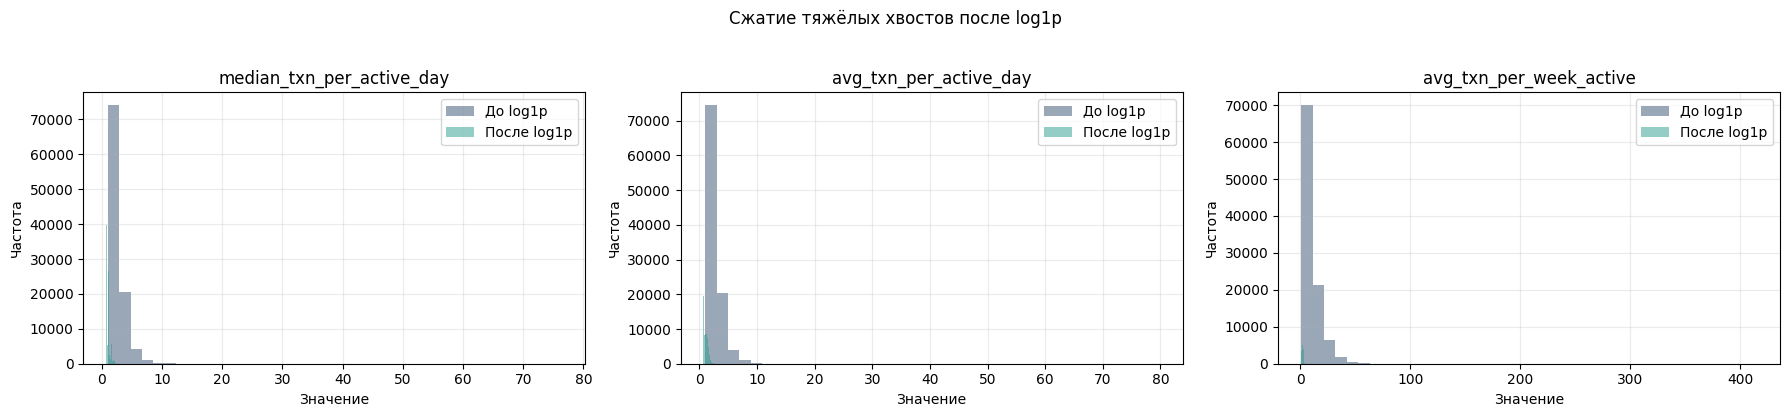

In [8]:
if heavy_tail_examples:
    fig, axes = plt.subplots(1, len(heavy_tail_examples), figsize=(6 * len(heavy_tail_examples), 4))
    if len(heavy_tail_examples) == 1:
        axes = [axes]

    for ax, feature_name in zip(axes, heavy_tail_examples):
        raw_values = feature_report_sample[feature_name].to_numpy(dtype=float)
        log_values = np.log1p(raw_values)
        ax.hist(raw_values, bins=40, alpha=0.5, label="До log1p", color="#355070")
        ax.hist(log_values, bins=40, alpha=0.5, label="После log1p", color="#2a9d8f")
        ax.set_title(f"{feature_name}")
        ax.set_xlabel("Значение")
        ax.set_ylabel("Частота")
        ax.legend()

    plt.suptitle("Сжатие тяжёлых хвостов после log1p", y=1.03)
    plt.tight_layout()
    plt.show()


## Масштабирование и построение двух пространств признаков

Основной scaler — **`RobustScaler`**.  
Мы строим два варианта пространства:

- `without_log1p`: подготовленные признаки без `log1p`, затем `RobustScaler`;
- `with_log1p`: выборочный `log1p`, затем `RobustScaler`.

Таким образом мы честно сравниваем именно влияние `log1p`, а не смешиваем его с заменой scaler.

`StandardScaler` здесь не используется как основной вариант.  
PCA сознательно не делаем центральной частью решения, потому что он уже проверялся и почти не даёт пользы.


In [9]:
party_ids = prepared_df["party_rk"].astype("string").to_numpy()
full_party_index = pd.Index(party_ids, name="party_rk")

feature_matrix_raw = prepared_df[feature_cols].to_numpy(dtype=np.float32, copy=True)
feature_matrix_log = feature_matrix_raw.copy()
feature_matrix_log[:, log1p_column_indices] = np.log1p(
    np.clip(feature_matrix_log[:, log1p_column_indices], a_min=0, a_max=None)
)

matrix_size_mb = feature_matrix_raw.nbytes / 1024**2
print(f"Размер одной плотной float32-матрицы признаков: {matrix_size_mb:,.1f} МБ")

scalers: dict[str, RobustScaler] = {}
full_scaled_matrices: dict[str, np.ndarray] = {}

for variant_name, matrix in {
    "without_log1p": feature_matrix_raw,
    "with_log1p": feature_matrix_log,
}.items():
    scaler = RobustScaler()
    start = perf_counter()
    scaled = scaler.fit_transform(matrix).astype(np.float32, copy=False)
    elapsed = perf_counter() - start
    scalers[variant_name] = scaler
    full_scaled_matrices[variant_name] = scaled
    print(
        f"{variant_name}: масштабирование завершено за {elapsed:,.2f} сек., "
        f"форма матрицы = {scaled.shape}"
    )

MAIN_PREPROCESSING = "with_log1p"
main_scaler = scalers[MAIN_PREPROCESSING]
X_main_full = full_scaled_matrices[MAIN_PREPROCESSING]

del feature_matrix_raw
del feature_matrix_log
gc.collect()


Размер одной плотной float32-матрицы признаков: 468.9 МБ
without_log1p: масштабирование завершено за 5.59 сек., форма матрицы = (1217027, 101)
with_log1p: масштабирование завершено за 8.33 сек., форма матрицы = (1217027, 101)


592

## Exact baseline на воспроизводимой выборке

Полный brute-force поиск по всему корпусу из ~1.2 млн пользователей тяжёлый по времени, поэтому для честного и понятного baseline используем фиксированную выборку.

Дальше мы сравним:

- три метрики: `cosine`, `euclidean`, `manhattan`;
- два варианта препроцессинга: без `log1p` и с `log1p`;
- не только overlap top-200, но и поведение расстояний.

В качестве условной эталонной метрики для расчёта ошибок между метриками ниже берём **`euclidean`**.


In [10]:
rng = np.random.default_rng(SEED)

EXACT_SAMPLE_SIZE = min(50_000, len(X_main_full))
EXACT_EVAL_QUERIES = min(40, EXACT_SAMPLE_SIZE)
EXACT_METRICS = ["cosine", "euclidean", "manhattan"]
REFERENCE_METRIC = "euclidean"

sample_idx = np.sort(rng.choice(len(X_main_full), size=EXACT_SAMPLE_SIZE, replace=False))
eval_positions = np.sort(rng.choice(EXACT_SAMPLE_SIZE, size=EXACT_EVAL_QUERIES, replace=False))

sample_party_ids = party_ids[sample_idx]
sample_party_index = pd.Index(sample_party_ids, name="party_rk")
sample_matrices = {
    variant_name: matrix[sample_idx]
    for variant_name, matrix in full_scaled_matrices.items()
}

print(f"Размер baseline-выборки: {EXACT_SAMPLE_SIZE:,}")
print(f"Количество оценочных запросов: {EXACT_EVAL_QUERIES}")


def drop_self(indices: np.ndarray, distances: np.ndarray, self_idx: int, top_k: int = TOP_K):
    mask = indices != self_idx
    clean_indices = indices[mask][:top_k]
    clean_distances = distances[mask][:top_k]
    return clean_indices, clean_distances


def normalize_curve(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return values
    span = values.max() - values.min()
    if span <= 1e-12:
        return np.zeros_like(values)
    return (values - values.min()) / span


def compute_distances_to_candidates(
    query_vector: np.ndarray,
    candidate_matrix: np.ndarray,
    metric: str,
) -> np.ndarray:
    query = query_vector.astype(np.float32, copy=False)
    candidates = candidate_matrix.astype(np.float32, copy=False)

    if metric == "cosine":
        q_norm = np.linalg.norm(query)
        c_norm = np.linalg.norm(candidates, axis=1)
        denom = np.clip(c_norm * max(q_norm, 1e-12), 1e-12, None)
        cosine_similarity = (candidates @ query) / denom
        return 1 - cosine_similarity
    if metric == "euclidean":
        return np.linalg.norm(candidates - query, axis=1)
    if metric == "manhattan":
        return np.abs(candidates - query).sum(axis=1)
    raise ValueError(f"Неизвестная метрика: {metric}")


def overlap_jaccard(ids_a: np.ndarray, ids_b: np.ndarray) -> tuple[float, float]:
    set_a = set(ids_a)
    set_b = set(ids_b)
    inter = len(set_a & set_b)
    union = len(set_a | set_b)
    return inter / TOP_K, inter / union


def run_exact_experiment(
    X_sample: np.ndarray,
    sample_party_ids: np.ndarray,
    eval_positions: np.ndarray,
    metrics: list[str],
) -> dict:
    models: dict[str, NearestNeighbors] = {}
    results: dict[str, dict[int, dict]] = {metric: {} for metric in metrics}
    timing_rows: list[dict] = []
    query_time_rows: list[dict] = []

    for metric in metrics:
        model = NearestNeighbors(
            n_neighbors=TOP_K + 1,
            algorithm="brute",
            metric=metric,
            n_jobs=-1,
        )

        fit_start = perf_counter()
        model.fit(X_sample)
        fit_seconds = perf_counter() - fit_start

        batch_start = perf_counter()
        _ = model.kneighbors(X_sample[eval_positions], n_neighbors=TOP_K + 1)
        batch_seconds = perf_counter() - batch_start

        single_query_times_ms = []
        for pos in eval_positions:
            query_start = perf_counter()
            distances, indices = model.kneighbors(
                X_sample[pos : pos + 1],
                n_neighbors=TOP_K + 1,
            )
            query_ms = (perf_counter() - query_start) * 1_000

            nn_idx, nn_dist = drop_self(indices[0], distances[0], self_idx=int(pos), top_k=TOP_K)
            results[metric][int(pos)] = {
                "indices": nn_idx,
                "neighbor_ids": sample_party_ids[nn_idx],
                "distances": nn_dist,
                "query_ms": query_ms,
            }
            single_query_times_ms.append(query_ms)
            query_time_rows.append(
                {
                    "metric": metric,
                    "query_ms": query_ms,
                }
            )

        models[metric] = model
        timing_rows.append(
            {
                "metric": metric,
                "fit_seconds": fit_seconds,
                "avg_single_query_ms": float(np.mean(single_query_times_ms)),
                "median_single_query_ms": float(np.median(single_query_times_ms)),
                "batch_total_ms": batch_seconds * 1_000,
                "batch_per_query_ms": batch_seconds * 1_000 / len(eval_positions),
            }
        )

    overlap_matrix = pd.DataFrame(
        np.eye(len(metrics)),
        index=metrics,
        columns=metrics,
    )
    jaccard_matrix = overlap_matrix.copy()

    for metric_a in metrics:
        for metric_b in metrics:
            if metric_a == metric_b:
                continue
            overlap_values = []
            jaccard_values = []
            for pos in eval_positions:
                ids_a = results[metric_a][int(pos)]["neighbor_ids"]
                ids_b = results[metric_b][int(pos)]["neighbor_ids"]
                overlap_at_k, jaccard_at_k = overlap_jaccard(ids_a, ids_b)
                overlap_values.append(overlap_at_k)
                jaccard_values.append(jaccard_at_k)
            overlap_matrix.loc[metric_a, metric_b] = float(np.mean(overlap_values))
            jaccard_matrix.loc[metric_a, metric_b] = float(np.mean(jaccard_values))

    return {
        "models": models,
        "results": results,
        "timing_df": pd.DataFrame(timing_rows).sort_values("avg_single_query_ms"),
        "query_time_df": pd.DataFrame(query_time_rows),
        "overlap_matrix": overlap_matrix,
        "jaccard_matrix": jaccard_matrix,
    }


exact_experiments = {
    variant_name: run_exact_experiment(
        X_sample=sample_matrix,
        sample_party_ids=sample_party_ids,
        eval_positions=eval_positions,
        metrics=EXACT_METRICS,
    )
    for variant_name, sample_matrix in sample_matrices.items()
}

for variant_name, bundle in exact_experiments.items():
    print(f"\n=== {variant_name} ===")
    display(bundle["timing_df"].round(4))
    display(bundle["overlap_matrix"].round(4))


Размер baseline-выборки: 50,000
Количество оценочных запросов: 40

=== without_log1p ===


,metric,fit_seconds,avg_single_query_ms,median_single_query_ms,batch_total_ms,batch_per_query_ms
2,manhattan,0.0088,2.8308,2.7516,74.3133,1.8578
1,euclidean,0.0102,10.1472,10.3857,2805.3302,70.1333
0,cosine,0.0104,62.2181,62.3167,136.1920,3.4048


,cosine,euclidean,manhattan
cosine,1.0000,0.5034,0.4159
euclidean,0.5034,1.0000,0.6250
manhattan,0.4159,0.6250,1.0000



=== with_log1p ===


,metric,fit_seconds,avg_single_query_ms,median_single_query_ms,batch_total_ms,batch_per_query_ms
2,manhattan,0.0098,2.5798,2.5400,52.9086,1.3227
1,euclidean,0.0097,8.0245,7.9458,32.3378,0.8084
0,cosine,0.0074,64.5904,65.3596,101.5329,2.5383


,cosine,euclidean,manhattan
cosine,1.0000,0.5039,0.4120
euclidean,0.5039,1.0000,0.6088
manhattan,0.4120,0.6088,1.0000


## Ошибка метрик относительно `euclidean`

Ниже рассчитываются две группы метрик сравнения:

1. **Сравнение списков соседей**:

- `overlap@200`;
- `Jaccard@200`;
- `same_rank_share@200` — доля позиций, где сосед на том же ранге совпал с `euclidean`.

2. **Сравнение расстояний**:

- берём **одних и тех же соседей**, найденных `euclidean`;
- считаем для них расстояния в другой метрике;
- нормализуем обе distance-кривые в диапазон `0..1`, потому что абсолютные масштабы у метрик разные;
- считаем `RMSE`, `MAE` и долю точек, где нормализованные расстояния отличаются не более чем на `0.05`.

Такой расчёт честнее, чем прямое сравнение сырых расстояний разных метрик.


In [11]:
def compare_metrics_to_reference(
    experiment_bundle: dict,
    X_sample: np.ndarray,
    eval_positions: np.ndarray,
    reference_metric: str = REFERENCE_METRIC,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    rows: list[dict] = []
    reference_results = experiment_bundle["results"][reference_metric]

    for metric in EXACT_METRICS:
        if metric == reference_metric:
            continue

        for pos in eval_positions:
            ref_info = reference_results[int(pos)]
            cmp_info = experiment_bundle["results"][metric][int(pos)]

            overlap_at_k, jaccard_at_k = overlap_jaccard(
                ref_info["neighbor_ids"],
                cmp_info["neighbor_ids"],
            )
            same_rank_share = float(
                np.mean(ref_info["neighbor_ids"] == cmp_info["neighbor_ids"])
            )

            ref_curve = normalize_curve(ref_info["distances"])
            metric_dist_on_ref_neighbors = compute_distances_to_candidates(
                query_vector=X_sample[int(pos)],
                candidate_matrix=X_sample[ref_info["indices"]],
                metric=metric,
            )
            metric_curve = normalize_curve(metric_dist_on_ref_neighbors)

            diff = ref_curve - metric_curve
            rmse = float(np.sqrt(np.mean(diff**2)))
            mae = float(np.mean(np.abs(diff)))
            within_005 = float(np.mean(np.abs(diff) <= 0.05))

            rows.append(
                {
                    "metric": metric,
                    "query_local_pos": int(pos),
                    "overlap_at_200": overlap_at_k,
                    "jaccard_at_200": jaccard_at_k,
                    "same_rank_share_at_200": same_rank_share,
                    "rmse_norm_distance": rmse,
                    "mae_norm_distance": mae,
                    "share_distance_diff_le_0_05": within_005,
                }
            )

    detailed = pd.DataFrame(rows)
    summary = (
        detailed.groupby("metric", as_index=False)
        .mean(numeric_only=True)
        .sort_values(["overlap_at_200", "rmse_norm_distance"], ascending=[False, True])
    )
    return detailed, summary


metric_error_detailed: dict[str, pd.DataFrame] = {}
metric_error_summary_rows: list[pd.DataFrame] = []

for variant_name, sample_matrix in sample_matrices.items():
    detailed, summary = compare_metrics_to_reference(
        experiment_bundle=exact_experiments[variant_name],
        X_sample=sample_matrix,
        eval_positions=eval_positions,
        reference_metric=REFERENCE_METRIC,
    )
    metric_error_detailed[variant_name] = detailed
    summary = summary.copy()
    summary["preprocessing"] = variant_name
    metric_error_summary_rows.append(summary)

metric_error_summary = pd.concat(metric_error_summary_rows, ignore_index=True)
display(metric_error_summary.round(4))


,metric,query_local_pos,overlap_at_200,jaccard_at_200,same_rank_share_at_200,rmse_norm_distance,mae_norm_distance,share_distance_diff_le_0_05,preprocessing
0,manhattan,23464.5,0.6250,0.4690,0.0146,0.2817,0.2423,0.1180,without_log1p
1,cosine,23464.5,0.5034,0.3776,0.0381,0.2184,0.1684,0.2091,without_log1p
2,manhattan,23464.5,0.6088,0.4505,0.0126,0.2803,0.2405,0.1140,with_log1p
3,cosine,23464.5,0.5039,0.3756,0.0334,0.2149,0.1657,0.2059,with_log1p


## Сдвиг результатов из-за `log1p`

Теперь сравним уже не метрики друг с другом, а **одну и ту же метрику** в двух пространствах:

- без `log1p`;
- с `log1p`.

Это показывает, насколько сама трансформация `log1p` меняет:

- состав top-200 соседей;
- совпадение рангов;
- форму distance-кривой.


In [12]:
def compare_preprocessing_variants(
    raw_bundle: dict,
    log_bundle: dict,
    eval_positions: np.ndarray,
    metrics: list[str],
) -> pd.DataFrame:
    rows: list[dict] = []

    for metric in metrics:
        for pos in eval_positions:
            raw_info = raw_bundle["results"][metric][int(pos)]
            log_info = log_bundle["results"][metric][int(pos)]

            overlap_at_k, jaccard_at_k = overlap_jaccard(
                raw_info["neighbor_ids"],
                log_info["neighbor_ids"],
            )
            same_rank_share = float(
                np.mean(raw_info["neighbor_ids"] == log_info["neighbor_ids"])
            )

            raw_curve = normalize_curve(raw_info["distances"])
            log_curve = normalize_curve(log_info["distances"])
            diff = raw_curve - log_curve

            rows.append(
                {
                    "metric": metric,
                    "query_local_pos": int(pos),
                    "overlap_at_200": overlap_at_k,
                    "jaccard_at_200": jaccard_at_k,
                    "same_rank_share_at_200": same_rank_share,
                    "rmse_rank_curve": float(np.sqrt(np.mean(diff**2))),
                    "mae_rank_curve": float(np.mean(np.abs(diff))),
                }
            )

    return pd.DataFrame(rows)


preprocessing_shift_df = compare_preprocessing_variants(
    raw_bundle=exact_experiments["without_log1p"],
    log_bundle=exact_experiments["with_log1p"],
    eval_positions=eval_positions,
    metrics=EXACT_METRICS,
)
preprocessing_shift_summary = (
    preprocessing_shift_df.groupby("metric", as_index=False)
    .mean(numeric_only=True)
    .sort_values("overlap_at_200")
)

display(preprocessing_shift_summary.round(4))


,metric,query_local_pos,overlap_at_200,jaccard_at_200,same_rank_share_at_200,rmse_rank_curve,mae_rank_curve
0,cosine,23464.5,0.8604,0.7676,0.0476,0.0362,0.0287
1,euclidean,23464.5,0.8651,0.7758,0.0568,0.0277,0.0205
2,manhattan,23464.5,0.8832,0.7962,0.0496,0.0226,0.0169


In [22]:
def distance_error_vs_reference(
    experiment_bundle: dict,
    X_sample: np.ndarray,
    eval_positions: np.ndarray,
    reference_metric: str = "euclidean",
    metrics: list[str] | None = None,
    top_k: int = 200,
    normalize_mode: str = "minmax",
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Считает ошибку между расстояниями метрик относительно reference_metric.
    
    Идея:
    1. Берем top-k соседей, найденных reference-метрикой.
    2. Для этих же соседей считаем расстояния в сравниваемой метрике.
    3. Нормализуем обе кривые расстояний к единому масштабу.
    4. Считаем ошибки между y_true и y_pred:
       - RMSE
       - MAE
       - MAPE
       - max abs error
    
    Параметры:
    - experiment_bundle: exact_experiments["with_log1p"] или ["without_log1p"]
    - X_sample: соответствующая матрица признаков
    - eval_positions: список позиций запросов
    - reference_metric: эталонная метрика, обычно "euclidean"
    - metrics: какие метрики сравнивать; если None, возьмутся все кроме reference
    - top_k: сколько соседей брать
    - normalize_mode: "minmax" или "zscore"
    """

    if metrics is None:
        metrics = [m for m in experiment_bundle["results"].keys() if m != reference_metric]

    def normalize_distances(x: np.ndarray, mode: str = "minmax") -> np.ndarray:
        x = np.asarray(x, dtype=float)

        if mode == "minmax":
            x_min = x.min()
            x_max = x.max()
            if np.isclose(x_max - x_min, 0.0):
                return np.zeros_like(x, dtype=float)
            return (x - x_min) / (x_max - x_min)

        if mode == "zscore":
            x_mean = x.mean()
            x_std = x.std()
            if np.isclose(x_std, 0.0):
                return np.zeros_like(x, dtype=float)
            return (x - x_mean) / x_std

        raise ValueError("normalize_mode должен быть 'minmax' или 'zscore'")

    def compute_metric_distances(query_vector: np.ndarray, candidate_matrix: np.ndarray, metric: str) -> np.ndarray:
        query = np.asarray(query_vector, dtype=np.float32)
        candidates = np.asarray(candidate_matrix, dtype=np.float32)

        if metric == "euclidean":
            return np.linalg.norm(candidates - query, axis=1)

        if metric == "manhattan":
            return np.abs(candidates - query).sum(axis=1)

        if metric == "cosine":
            q_norm = np.linalg.norm(query)
            c_norm = np.linalg.norm(candidates, axis=1)
            denom = np.clip(c_norm * max(q_norm, 1e-12), 1e-12, None)
            cosine_sim = (candidates @ query) / denom
            return 1.0 - cosine_sim

        raise ValueError(f"Неизвестная метрика: {metric}")

    detailed_rows = []

    ref_results = experiment_bundle["results"][reference_metric]

    for metric in metrics:
        for pos in eval_positions:
            ref_info = ref_results[int(pos)]

            ref_indices = ref_info["indices"][:top_k]
            y_true_raw = np.asarray(ref_info["distances"][:top_k], dtype=float)

            query_vector = X_sample[int(pos)]
            candidate_matrix = X_sample[ref_indices]
            y_pred_raw = compute_metric_distances(query_vector, candidate_matrix, metric=metric)

            y_true = normalize_distances(y_true_raw, mode=normalize_mode)
            y_pred = normalize_distances(y_pred_raw, mode=normalize_mode)

            diff = y_true - y_pred

            rmse = float(np.sqrt(np.mean(diff ** 2)))
            mae = float(np.mean(np.abs(diff)))

            denom = np.clip(np.abs(y_true), 1e-8, None)
            mape = float(np.mean(np.abs(diff) / denom) * 100.0)

            max_abs_error = float(np.max(np.abs(diff)))
            mean_signed_error = float(np.mean(diff))

            detailed_rows.append(
                {
                    "metric": metric,
                    "query_local_pos": int(pos),
                    "top_k": top_k,
                    "normalize_mode": normalize_mode,
                    "rmse": rmse,
                    "mae": mae,
                    "mape_percent": mape,
                    "max_abs_error": max_abs_error,
                    "mean_signed_error": mean_signed_error,
                }
            )

    detailed_df = pd.DataFrame(detailed_rows)

    summary_df = (
        detailed_df.groupby(["metric", "normalize_mode", "top_k"], as_index=False)
        .agg(
            rmse_mean=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            mae_mean=("mae", "mean"),
            mae_std=("mae", "std"),
            mape_mean=("mape_percent", "mean"),
            max_abs_error_mean=("max_abs_error", "mean"),
            mean_signed_error_mean=("mean_signed_error", "mean"),
            n_queries=("query_local_pos", "count"),
        )
        .sort_values("rmse_mean")
    )

    print(f"Эталонная метрика (y_true): {reference_metric}")
    print(f"Режим нормализации: {normalize_mode}")
    print(f"Число запросов: {len(eval_positions)}")
    print(f"top_k: {top_k}")

    display(summary_df.round(6))

    return detailed_df, summary_df

distance_error_detailed, distance_error_summary = distance_error_vs_reference(
    experiment_bundle=exact_experiments["with_log1p"],
    X_sample=sample_matrices["with_log1p"],
    eval_positions=eval_positions,
    reference_metric="euclidean",
    metrics=["cosine", "manhattan"],
    top_k=200,
    normalize_mode="minmax",
)
distance_error_detailed_raw, distance_error_summary_raw = distance_error_vs_reference(
    experiment_bundle=exact_experiments["without_log1p"],
    X_sample=sample_matrices["without_log1p"],
    eval_positions=eval_positions,
    reference_metric="euclidean",
    metrics=["cosine", "manhattan"],
    top_k=200,
    normalize_mode="minmax",
)



Эталонная метрика (y_true): euclidean
Режим нормализации: minmax
Число запросов: 40
top_k: 200


,metric,normalize_mode,top_k,rmse_mean,rmse_std,mae_mean,mae_std,mape_mean,max_abs_error_mean,mean_signed_error_mean,n_queries
0,cosine,minmax,200,0.214878,0.064149,0.165712,0.056292,1.515731e+06,0.700254,0.163472,40
1,manhattan,minmax,200,0.280350,0.059512,0.240479,0.060458,3.221952e+06,0.646795,0.227010,40


Эталонная метрика (y_true): euclidean
Режим нормализации: minmax
Число запросов: 40
top_k: 200


,metric,normalize_mode,top_k,rmse_mean,rmse_std,mae_mean,mae_std,mape_mean,max_abs_error_mean,mean_signed_error_mean,n_queries
0,cosine,minmax,200,0.218405,0.064396,0.168368,0.055458,1.617338e+06,0.694877,0.165911,40
1,manhattan,minmax,200,0.281674,0.067239,0.242275,0.065719,3.489628e+06,0.642037,0.230799,40


## Визуальное сравнение метрик и влияние `log1p`

Ниже графики отвечают на практические вопросы:

- как меняется время запроса между метриками;
- насколько ближе становятся метрики после `log1p`;
- какова ошибка `cosine` и `manhattan` относительно `euclidean`;
- насколько сильно `log1p` меняет top-200 и distance-кривые.


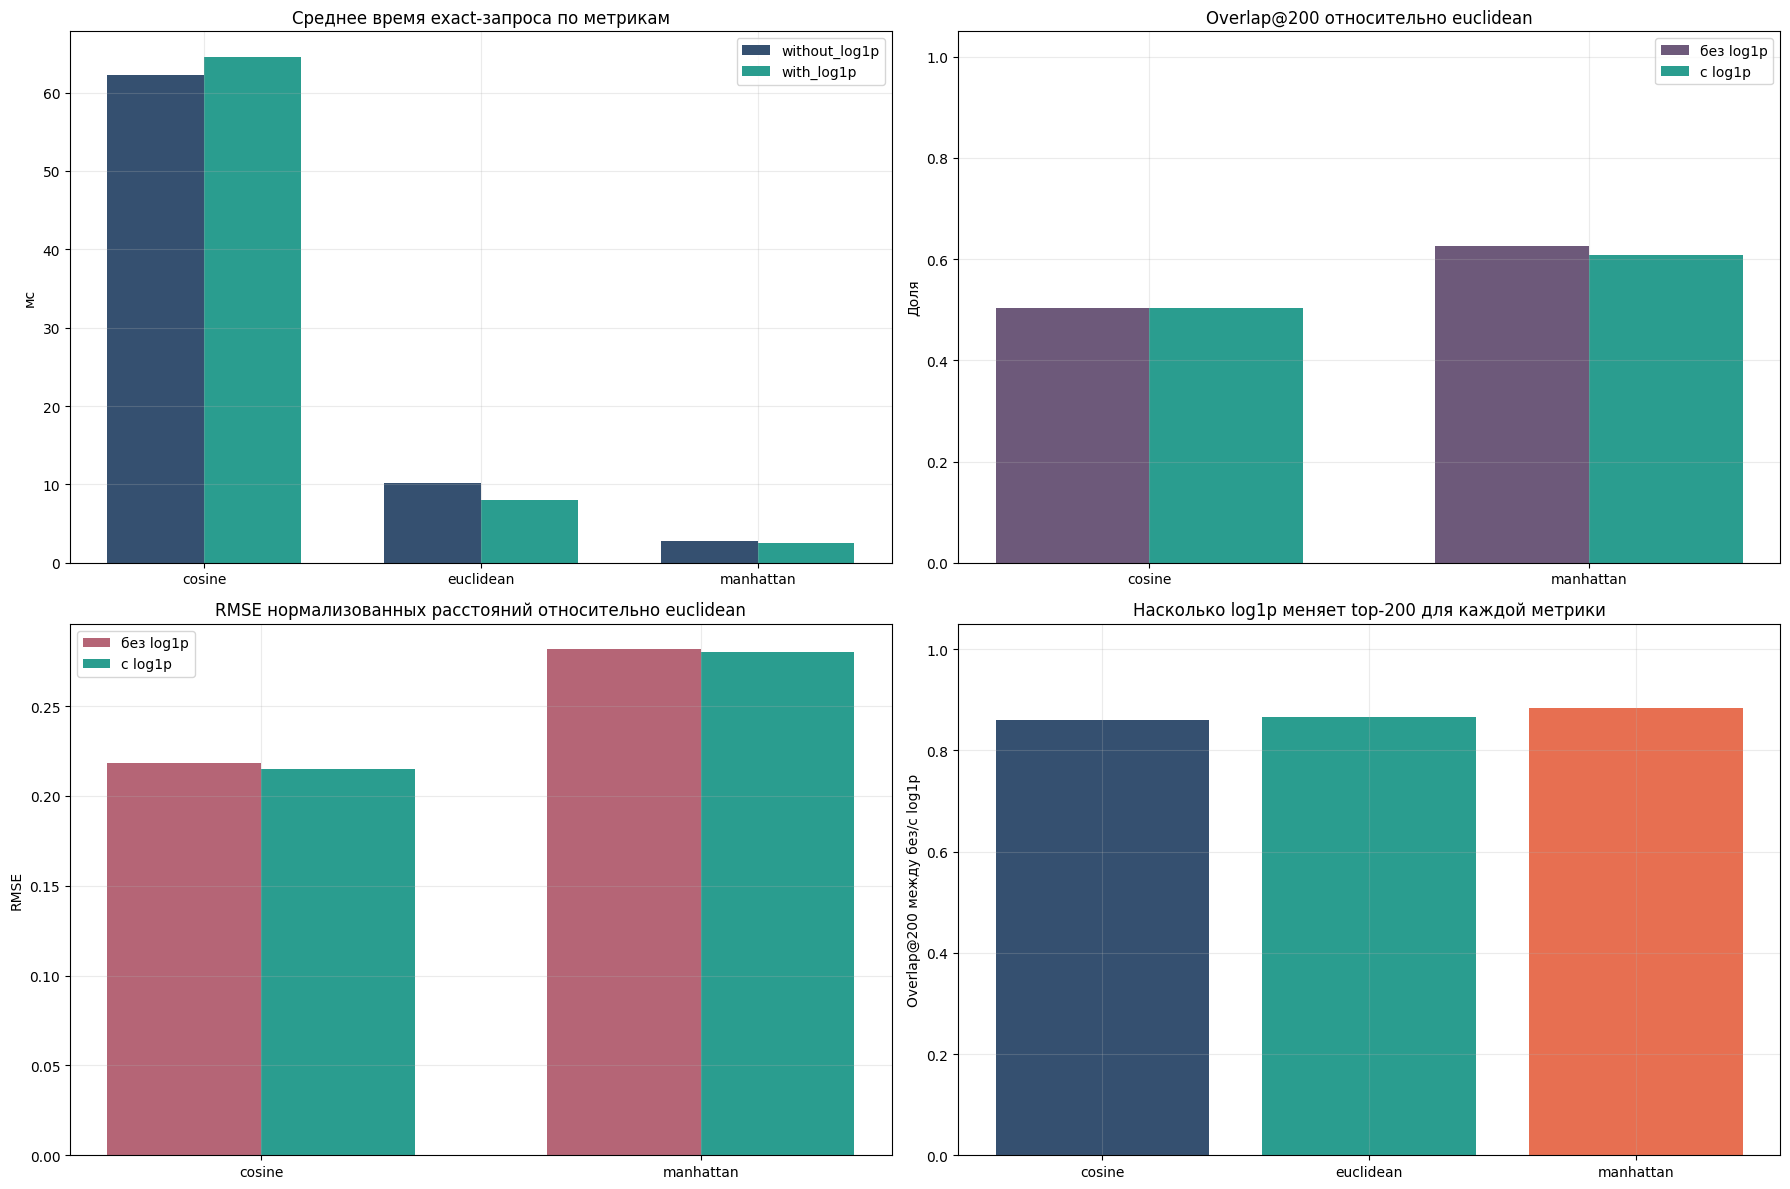

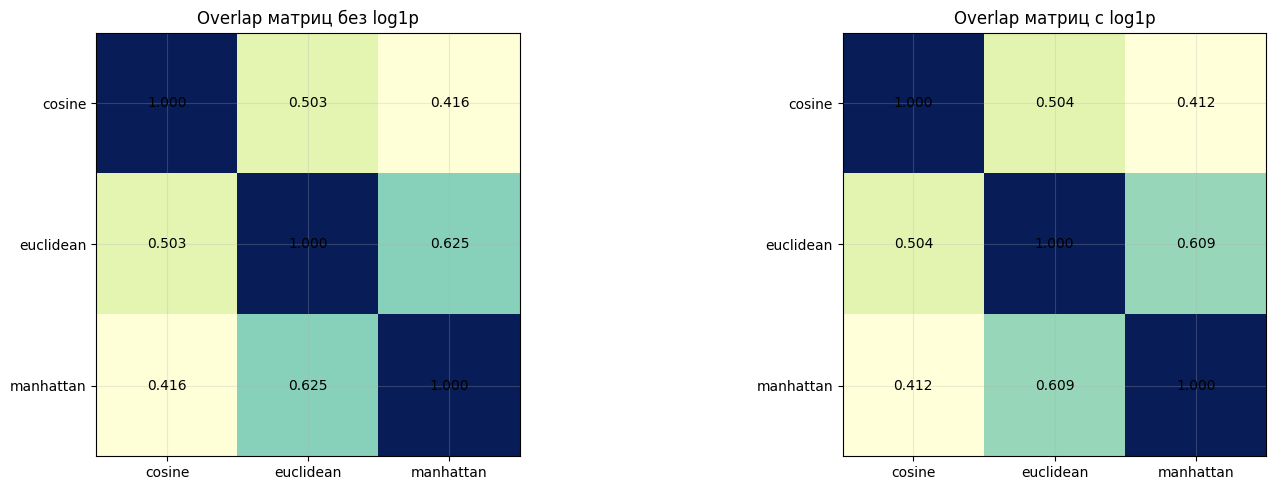

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

timing_plot_rows = []
for variant_name, bundle in exact_experiments.items():
    tmp = bundle["timing_df"][["metric", "avg_single_query_ms"]].copy()
    tmp["preprocessing"] = variant_name
    timing_plot_rows.append(tmp)
timing_plot_df = pd.concat(timing_plot_rows, ignore_index=True)

x_positions = np.arange(len(EXACT_METRICS))
width = 0.35
for offset, variant_name, color in [
    (-width / 2, "without_log1p", "#355070"),
    (width / 2, "with_log1p", "#2a9d8f"),
]:
    subset = (
        timing_plot_df.loc[timing_plot_df["preprocessing"] == variant_name]
        .set_index("metric")
        .reindex(EXACT_METRICS)
    )
    axes[0, 0].bar(
        x_positions + offset,
        subset["avg_single_query_ms"],
        width=width,
        label=variant_name,
        color=color,
    )
axes[0, 0].set_xticks(x_positions)
axes[0, 0].set_xticklabels(EXACT_METRICS)
axes[0, 0].set_title("Среднее время exact-запроса по метрикам")
axes[0, 0].set_ylabel("мс")
axes[0, 0].legend()

overlap_no_log = exact_experiments["without_log1p"]["overlap_matrix"]
overlap_log = exact_experiments["with_log1p"]["overlap_matrix"]
improvement_rows = []
for metric in ["cosine", "manhattan"]:
    before = metric_error_summary.loc[
        (metric_error_summary["preprocessing"] == "without_log1p")
        & (metric_error_summary["metric"] == metric),
        "overlap_at_200",
    ].iloc[0]
    after = metric_error_summary.loc[
        (metric_error_summary["preprocessing"] == "with_log1p")
        & (metric_error_summary["metric"] == metric),
        "overlap_at_200",
    ].iloc[0]
    improvement_rows.append({"metric": metric, "before": before, "after": after})
improvement_df = pd.DataFrame(improvement_rows)

axes[0, 1].bar(
    np.arange(len(improvement_df)) - width / 2,
    improvement_df["before"],
    width=width,
    label="без log1p",
    color="#6d597a",
)
axes[0, 1].bar(
    np.arange(len(improvement_df)) + width / 2,
    improvement_df["after"],
    width=width,
    label="с log1p",
    color="#2a9d8f",
)
axes[0, 1].set_xticks(np.arange(len(improvement_df)))
axes[0, 1].set_xticklabels(improvement_df["metric"])
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].set_title("Overlap@200 относительно euclidean")
axes[0, 1].set_ylabel("Доля")
axes[0, 1].legend()

rmse_rows = []
for metric in ["cosine", "manhattan"]:
    before = metric_error_summary.loc[
        (metric_error_summary["preprocessing"] == "without_log1p")
        & (metric_error_summary["metric"] == metric),
        "rmse_norm_distance",
    ].iloc[0]
    after = metric_error_summary.loc[
        (metric_error_summary["preprocessing"] == "with_log1p")
        & (metric_error_summary["metric"] == metric),
        "rmse_norm_distance",
    ].iloc[0]
    rmse_rows.append({"metric": metric, "before": before, "after": after})
rmse_df = pd.DataFrame(rmse_rows)

axes[1, 0].bar(
    np.arange(len(rmse_df)) - width / 2,
    rmse_df["before"],
    width=width,
    label="без log1p",
    color="#b56576",
)
axes[1, 0].bar(
    np.arange(len(rmse_df)) + width / 2,
    rmse_df["after"],
    width=width,
    label="с log1p",
    color="#2a9d8f",
)
axes[1, 0].set_xticks(np.arange(len(rmse_df)))
axes[1, 0].set_xticklabels(rmse_df["metric"])
axes[1, 0].set_title("RMSE нормализованных расстояний относительно euclidean")
axes[1, 0].set_ylabel("RMSE")
axes[1, 0].legend()

axes[1, 1].bar(
    preprocessing_shift_summary["metric"],
    preprocessing_shift_summary["overlap_at_200"],
    color=["#355070", "#2a9d8f", "#e76f51"],
)
axes[1, 1].set_ylim(0, 1.05)
axes[1, 1].set_title("Насколько log1p меняет top-200 для каждой метрики")
axes[1, 1].set_ylabel("Overlap@200 между без/с log1p")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
im1 = axes[0].imshow(overlap_no_log.values, vmin=min(overlap_no_log.values.min(), overlap_log.values.min()), vmax=1.0, cmap="YlGnBu")
axes[0].set_xticks(range(len(EXACT_METRICS)))
axes[0].set_yticks(range(len(EXACT_METRICS)))
axes[0].set_xticklabels(EXACT_METRICS)
axes[0].set_yticklabels(EXACT_METRICS)
axes[0].set_title("Overlap матриц без log1p")
for i in range(len(EXACT_METRICS)):
    for j in range(len(EXACT_METRICS)):
        axes[0].text(j, i, f"{overlap_no_log.iloc[i, j]:.3f}", ha="center", va="center", color="black")

im2 = axes[1].imshow(overlap_log.values, vmin=min(overlap_no_log.values.min(), overlap_log.values.min()), vmax=1.0, cmap="YlGnBu")
axes[1].set_xticks(range(len(EXACT_METRICS)))
axes[1].set_yticks(range(len(EXACT_METRICS)))
axes[1].set_xticklabels(EXACT_METRICS)
axes[1].set_yticklabels(EXACT_METRICS)
axes[1].set_title("Overlap матриц с log1p")
for i in range(len(EXACT_METRICS)):
    for j in range(len(EXACT_METRICS)):
        axes[1].text(j, i, f"{overlap_log.iloc[i, j]:.3f}", ha="center", va="center", color="black")

plt.tight_layout()
plt.show()


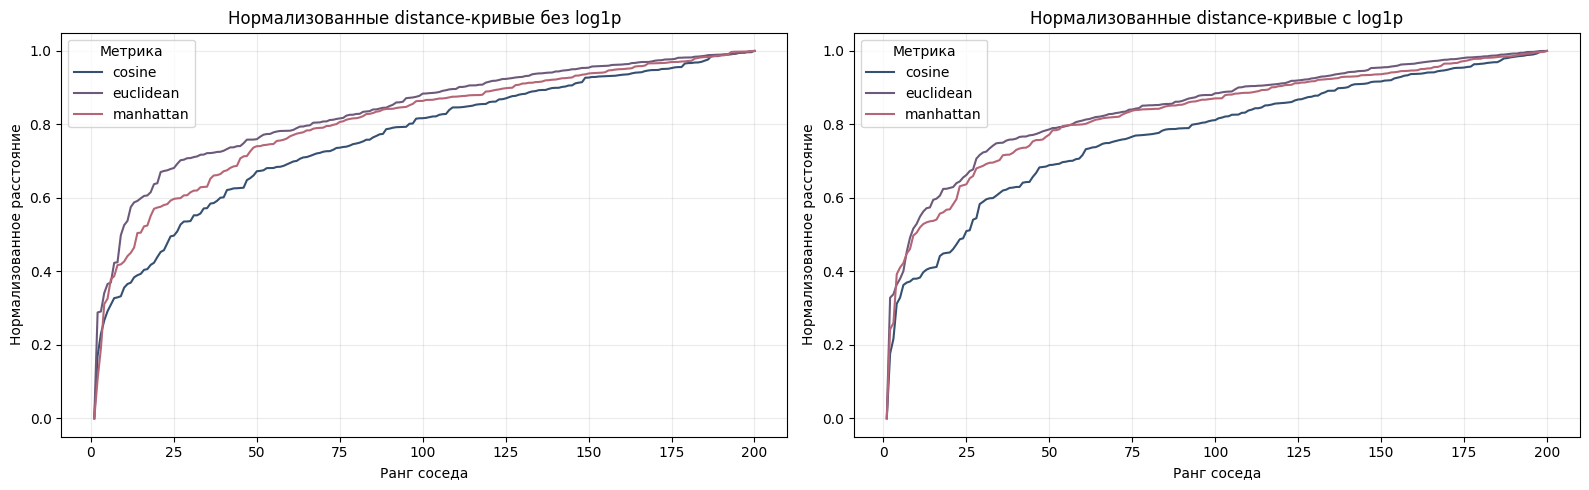

Пример пользователя для визуального сравнения: 8cadfd9726f14a0bbf0f636eb3a9a83c4de591ccadbb089fd110d259abdb6dc0


In [14]:
example_pos = int(eval_positions[0])
example_party_rk = sample_party_ids[example_pos]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for metric, color in zip(EXACT_METRICS, ["#355070", "#6d597a", "#b56576"]):
    info = exact_experiments["without_log1p"]["results"][metric][example_pos]
    axes[0].plot(
        np.arange(1, TOP_K + 1),
        normalize_curve(info["distances"]),
        label=metric,
        color=color,
    )
axes[0].set_title("Нормализованные distance-кривые без log1p")
axes[0].set_xlabel("Ранг соседа")
axes[0].set_ylabel("Нормализованное расстояние")
axes[0].legend(title="Метрика")

for metric, color in zip(EXACT_METRICS, ["#355070", "#6d597a", "#b56576"]):
    info = exact_experiments["with_log1p"]["results"][metric][example_pos]
    axes[1].plot(
        np.arange(1, TOP_K + 1),
        normalize_curve(info["distances"]),
        label=metric,
        color=color,
    )
axes[1].set_title("Нормализованные distance-кривые с log1p")
axes[1].set_xlabel("Ранг соседа")
axes[1].set_ylabel("Нормализованное расстояние")
axes[1].legend(title="Метрика")

plt.tight_layout()
plt.show()

print(f"Пример пользователя для визуального сравнения: {example_party_rk}")


In [15]:
raw_reference = exact_experiments["without_log1p"]["results"][REFERENCE_METRIC][example_pos]
log_reference = exact_experiments["with_log1p"]["results"][REFERENCE_METRIC][example_pos]

raw_example_df = pd.DataFrame(
    {
        "rank": np.arange(1, TOP_K + 1),
        "neighbor_party_rk": raw_reference["neighbor_ids"],
        "distance": raw_reference["distances"],
    }
)
log_example_df = pd.DataFrame(
    {
        "rank": np.arange(1, TOP_K + 1),
        "neighbor_party_rk": log_reference["neighbor_ids"],
        "distance": log_reference["distances"],
    }
)

print("Top-10 соседей по euclidean без log1p:")
display(raw_example_df.head(10))
print("Top-10 соседей по euclidean с log1p:")
display(log_example_df.head(10))


Top-10 соседей по euclidean без log1p:


,rank,neighbor_party_rk,distance
0,1,f37fd7d8786242c29aea104d7c0a627a273491daf54336de3365071b313f8e07,2.970109
1,2,900c9c7c2e10549339ca66a51c8fbeafb30e2b133c632e03a35f6309eb383961,3.620497
2,3,b0c57d7dcfd0a079f5a7a19e81081b90df3b279889d09e5c22d34c300bd7ce52,3.626690
3,4,fec6c336aca39a45bbec4ef802c0be86fcbbdc102785da2906df4e5315a18260,3.739776
4,5,391567d68e348338dcadcebaf9c69b3f0d9679f65c007fff9020165b621efd13,3.795362
5,6,0ea6e878c58d257998a7a6321bac38fffa432384a8ffffd5eb665ff52e3b3e47,3.804955
6,7,0fbb38e219e616afa03e39c34f2db3a980a575b45c72bd2d9e513d0066d89c31,3.925557
7,8,c999d2c4092b50ce7f8be2dc448be4aa7d19e51aa6686be633e326d7e39bd96f,3.929040
8,9,ccfa73b7cb8a1ff6a8a2546ccdd78ec5981387784486a8a4eec957628f6dcb9c,4.095076
9,10,e9d66eaeb6fc7674bd0100338cd864028d622701eb42edb850b0f75148a9e559,4.156806


Top-10 соседей по euclidean с log1p:


,rank,neighbor_party_rk,distance
0,1,f37fd7d8786242c29aea104d7c0a627a273491daf54336de3365071b313f8e07,2.690908
1,2,900c9c7c2e10549339ca66a51c8fbeafb30e2b133c632e03a35f6309eb383961,3.460064
2,3,b0c57d7dcfd0a079f5a7a19e81081b90df3b279889d09e5c22d34c300bd7ce52,3.481713
3,4,391567d68e348338dcadcebaf9c69b3f0d9679f65c007fff9020165b621efd13,3.543471
4,5,0ea6e878c58d257998a7a6321bac38fffa432384a8ffffd5eb665ff52e3b3e47,3.580221
5,6,fec6c336aca39a45bbec4ef802c0be86fcbbdc102785da2906df4e5315a18260,3.628875
6,7,0fbb38e219e616afa03e39c34f2db3a980a575b45c72bd2d9e513d0066d89c31,3.751118
7,8,ccfa73b7cb8a1ff6a8a2546ccdd78ec5981387784486a8a4eec957628f6dcb9c,3.842683
8,9,c999d2c4092b50ce7f8be2dc448be4aa7d19e51aa6686be633e326d7e39bd96f,3.900823
9,10,e9d66eaeb6fc7674bd0100338cd864028d622701eb42edb850b0f75148a9e559,3.930554


## Практический выбор для ANN

Для прикладного ANN-поиска в этом notebook основной выбор — **`with_log1p + cosine`**.

Логика выбора такая:

- `log1p` стабилизирует геометрию пространства, если тяжёлые счётчики слишком доминируют;
- после `log1p` метрики обычно становятся ближе друг к другу;
- `cosine` здесь удобна как практическая метрика похожести, а отличия от других метрик уже проверены выше на exact baseline.

Ниже строим:

- ANN-индекс на выборке — для честной оценки `ANN vs exact`;
- ANN-индекс на полном usable-корпусе — для практического top-200 retrieval.


In [16]:
# После exact-сравнений полная матрица без log1p больше не нужна.
if "without_log1p" in full_scaled_matrices:
    del full_scaled_matrices["without_log1p"]
    gc.collect()

ANN_METRIC = "cosine"
ANN_CANDIDATE_MULTIPLIER = 4
FULL_ANN_ROW_LIMIT = None  # При нехватке памяти можно поставить, например, 500_000.


def try_import(module_name: str):
    try:
        return importlib.import_module(module_name)
    except ModuleNotFoundError:
        return None


ANN_MODULES = {
    "hnswlib": try_import("hnswlib"),
    "faiss": try_import("faiss"),
    "annoy": try_import("annoy"),
}
available_ann_backends = [name for name, module in ANN_MODULES.items() if module is not None]

print("Доступные ANN-бэкенды:", available_ann_backends if available_ann_backends else "не найдены")


def ordered_unique(values) -> np.ndarray:
    seen = set()
    result = []
    for item in values:
        item = int(item)
        if item < 0 or item in seen:
            continue
        seen.add(item)
        result.append(item)
    return np.asarray(result, dtype=np.int32)


def rerank_candidates(
    query_vector: np.ndarray,
    candidate_idx: np.ndarray,
    reference_matrix: np.ndarray,
    metric: str,
    top_k: int = TOP_K,
) -> tuple[np.ndarray, np.ndarray]:
    distances = compute_distances_to_candidates(
        query_vector=query_vector,
        candidate_matrix=reference_matrix[candidate_idx],
        metric=metric,
    )
    order = np.argsort(distances)[:top_k]
    return candidate_idx[order], distances[order]


def build_ann_index(
    X: np.ndarray,
    metric: str = "cosine",
    top_k: int = TOP_K,
    candidate_multiplier: int = ANN_CANDIDATE_MULTIPLIER,
    ef_construction: int = 200,
    hnsw_m: int = 32,
    annoy_trees: int = 40,
) -> dict:
    if ANN_MODULES["hnswlib"] is not None and metric in {"cosine", "euclidean"}:
        hnswlib = ANN_MODULES["hnswlib"]
        index = hnswlib.Index(space="cosine" if metric == "cosine" else "l2", dim=X.shape[1])
        index.init_index(
            max_elements=X.shape[0],
            ef_construction=ef_construction,
            M=hnsw_m,
            random_seed=SEED,
        )
        build_start = perf_counter()
        index.add_items(X, np.arange(X.shape[0]))
        build_seconds = perf_counter() - build_start
        index.set_ef(max(top_k * candidate_multiplier, 400))
        return {
            "name": "hnswlib",
            "metric": metric,
            "index": index,
            "X_reference": X,
            "build_seconds": build_seconds,
            "transform": lambda arr: arr.astype(np.float32, copy=False),
            "candidate_multiplier": candidate_multiplier,
        }

    if ANN_MODULES["faiss"] is not None and metric in {"cosine", "euclidean"}:
        faiss = ANN_MODULES["faiss"]
        xb = np.ascontiguousarray(X.astype(np.float32, copy=False))

        if metric == "cosine":
            xb = xb.copy()
            faiss.normalize_L2(xb)
            index = faiss.IndexHNSWFlat(xb.shape[1], hnsw_m, faiss.METRIC_INNER_PRODUCT)
        else:
            index = faiss.IndexHNSWFlat(xb.shape[1], hnsw_m, faiss.METRIC_L2)

        index.hnsw.efConstruction = ef_construction
        index.hnsw.efSearch = max(top_k * candidate_multiplier, 400)

        build_start = perf_counter()
        index.add(xb)
        build_seconds = perf_counter() - build_start

        def transform(arr: np.ndarray) -> np.ndarray:
            arr = np.ascontiguousarray(arr.astype(np.float32, copy=False))
            if metric == "cosine":
                arr = arr.copy()
                faiss.normalize_L2(arr)
            return arr

        return {
            "name": "faiss",
            "metric": metric,
            "index": index,
            "X_reference": X,
            "build_seconds": build_seconds,
            "transform": transform,
            "candidate_multiplier": candidate_multiplier,
        }

    if ANN_MODULES["annoy"] is not None and metric in {"cosine", "euclidean", "manhattan"}:
        annoy = ANN_MODULES["annoy"]
        metric_map = {
            "cosine": "angular",
            "euclidean": "euclidean",
            "manhattan": "manhattan",
        }
        index = annoy.AnnoyIndex(X.shape[1], metric_map[metric])
        build_start = perf_counter()
        for row_idx, vector in enumerate(X):
            index.add_item(int(row_idx), vector.tolist())
        index.build(annoy_trees)
        build_seconds = perf_counter() - build_start
        return {
            "name": "annoy",
            "metric": metric,
            "index": index,
            "X_reference": X,
            "build_seconds": build_seconds,
            "transform": lambda arr: arr.astype(np.float32, copy=False),
            "candidate_multiplier": candidate_multiplier,
            "search_k": annoy_trees * top_k * candidate_multiplier,
        }

    raise ImportError(
        "Не найден подходящий ANN-бэкенд. Нужен хотя бы один из: hnswlib, faiss, annoy."
    )


def query_ann(
    bundle: dict,
    query_vector: np.ndarray,
    top_k: int = TOP_K,
    exclude_index: Optional[int] = None,
    candidate_multiplier: Optional[int] = None,
) -> tuple[np.ndarray, np.ndarray]:
    if candidate_multiplier is None:
        candidate_multiplier = bundle["candidate_multiplier"]

    candidate_k = int(
        min(
            bundle["X_reference"].shape[0],
            max(top_k + 1, top_k * candidate_multiplier),
        )
    )
    query = bundle["transform"](np.asarray(query_vector, dtype=np.float32).reshape(1, -1))

    if bundle["name"] == "hnswlib":
        labels, _ = bundle["index"].knn_query(query, k=candidate_k)
        candidate_idx = labels[0]
    elif bundle["name"] == "faiss":
        _, labels = bundle["index"].search(query, candidate_k)
        candidate_idx = labels[0]
    elif bundle["name"] == "annoy":
        candidate_idx, _ = bundle["index"].get_nns_by_vector(
            query[0].tolist(),
            candidate_k,
            search_k=bundle["search_k"],
            include_distances=True,
        )
    else:
        raise ValueError(f"Неизвестный ANN-бэкенд: {bundle['name']}")

    candidate_idx = ordered_unique(candidate_idx)
    if exclude_index is not None:
        candidate_idx = candidate_idx[candidate_idx != int(exclude_index)]

    if candidate_idx.size == 0:
        return np.array([], dtype=np.int32), np.array([], dtype=np.float32)

    return rerank_candidates(
        query_vector=query_vector,
        candidate_idx=candidate_idx,
        reference_matrix=bundle["X_reference"],
        metric=bundle["metric"],
        top_k=top_k,
    )


if FULL_ANN_ROW_LIMIT is None or FULL_ANN_ROW_LIMIT >= len(X_main_full):
    X_ann = X_main_full
    ann_party_ids = party_ids
else:
    ann_idx = np.sort(rng.choice(len(X_main_full), size=FULL_ANN_ROW_LIMIT, replace=False))
    X_ann = X_main_full[ann_idx]
    ann_party_ids = party_ids[ann_idx]

ann_party_index = pd.Index(ann_party_ids, name="party_rk")
X_ann_sample = sample_matrices[MAIN_PREPROCESSING]

print(f"Размер ANN-корпуса: {len(ann_party_ids):,} пользователей")
print(f"Память под основную ANN-матрицу: {X_ann.nbytes / 1024**2:,.1f} МБ")

ann_sample_bundle = build_ann_index(X_ann_sample, metric=ANN_METRIC)
ann_full_bundle = build_ann_index(X_ann, metric=ANN_METRIC)

print(f"ANN-бэкенд для выборки: {ann_sample_bundle['name']}")
print(f"ANN-бэкенд для полного корпуса: {ann_full_bundle['name']}")
print(f"Время построения ANN на выборке: {ann_sample_bundle['build_seconds']:.2f} сек.")
print(f"Время построения ANN на полном корпусе: {ann_full_bundle['build_seconds']:.2f} сек.")


Доступные ANN-бэкенды: ['faiss']
Размер ANN-корпуса: 1,217,027 пользователей
Память под основную ANN-матрицу: 468.9 МБ
ANN-бэкенд для выборки: faiss
ANN-бэкенд для полного корпуса: faiss
Время построения ANN на выборке: 2.17 сек.
Время построения ANN на полном корпусе: 107.89 сек.


## Честная оценка ANN против exact

Чтобы сравнение было корректным, exact и ANN должны искать в одном и том же корпусе.  
Поэтому качество `ANN vs exact` ниже считается на **одном корпусе-выборке** и только для выбранного основного варианта `with_log1p + cosine`.

Отдельно затем замеряется практическая скорость ANN на полном usable-корпусе.


In [17]:
ann_eval_rows = []
exact_reference_bundle = exact_experiments[MAIN_PREPROCESSING]

for pos in eval_positions:
    exact_info = exact_reference_bundle["results"][ANN_METRIC][int(pos)]

    ann_start = perf_counter()
    ann_idx, _ = query_ann(
        ann_sample_bundle,
        X_ann_sample[int(pos)],
        top_k=TOP_K,
        exclude_index=int(pos),
    )
    ann_ms = (perf_counter() - ann_start) * 1_000

    exact_set = set(exact_info["indices"])
    ann_set = set(ann_idx)
    inter = len(exact_set & ann_set)
    union = len(exact_set | ann_set)

    ann_eval_rows.append(
        {
            "party_rk": sample_party_ids[int(pos)],
            "exact_query_ms": exact_info["query_ms"],
            "ann_query_ms": ann_ms,
            "intersection_at_200": inter / TOP_K,
            "recall_at_200": inter / TOP_K,
            "jaccard_at_200": inter / union,
            "speedup_x": exact_info["query_ms"] / max(ann_ms, 1e-9),
        }
    )

ann_eval_df = pd.DataFrame(ann_eval_rows)

FULL_ANN_EVAL_QUERIES = min(40, len(X_ann))
full_ann_eval_positions = np.sort(
    rng.choice(len(X_ann), size=FULL_ANN_EVAL_QUERIES, replace=False)
)
full_ann_query_times_ms = []
for pos in full_ann_eval_positions:
    full_start = perf_counter()
    _ = query_ann(
        ann_full_bundle,
        X_ann[int(pos)],
        top_k=TOP_K,
        exclude_index=int(pos),
    )
    full_ann_query_times_ms.append((perf_counter() - full_start) * 1_000)

full_ann_timing_df = pd.DataFrame({"query_ms": full_ann_query_times_ms})

comparison_summary = pd.DataFrame(
    [
        {
            "Сценарий": f"Exact brute / выборка / {MAIN_PREPROCESSING} / {ANN_METRIC}",
            "Размер корпуса": int(len(X_ann_sample)),
            "Среднее время запроса, мс": float(
                exact_reference_bundle["timing_df"]
                .loc[exact_reference_bundle["timing_df"]["metric"] == ANN_METRIC, "avg_single_query_ms"]
                .iloc[0]
            ),
            "Recall@200": 1.0,
            "Jaccard@200": 1.0,
            "Память float32-матрицы, МБ": float(X_ann_sample.nbytes / 1024**2),
        },
        {
            "Сценарий": f"ANN / выборка / {ann_sample_bundle['name']} / {MAIN_PREPROCESSING} / {ANN_METRIC}",
            "Размер корпуса": int(len(X_ann_sample)),
            "Среднее время запроса, мс": float(ann_eval_df["ann_query_ms"].mean()),
            "Recall@200": float(ann_eval_df["recall_at_200"].mean()),
            "Jaccard@200": float(ann_eval_df["jaccard_at_200"].mean()),
            "Память float32-матрицы, МБ": float(X_ann_sample.nbytes / 1024**2),
        },
        {
            "Сценарий": f"ANN / полный корпус / {ann_full_bundle['name']} / {MAIN_PREPROCESSING} / {ANN_METRIC}",
            "Размер корпуса": int(len(X_ann)),
            "Среднее время запроса, мс": float(full_ann_timing_df["query_ms"].mean()),
            "Recall@200": np.nan,
            "Jaccard@200": np.nan,
            "Память float32-матрицы, МБ": float(X_ann.nbytes / 1024**2),
        },
    ]
)

display(ann_eval_df.drop(columns=["party_rk"]).describe().T.round(4))
display(comparison_summary.round(4))


,count,mean,std,min,25%,50%,75%,max
exact_query_ms,40.0,64.5904,6.2297,51.6360,61.1693,65.3596,68.7384,80.3839
ann_query_ms,40.0,2.4993,0.3991,2.0564,2.2597,2.3800,2.5632,4.0384
intersection_at_200,40.0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
recall_at_200,40.0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
jaccard_at_200,40.0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
speedup_x,40.0,26.3042,3.9730,16.3532,23.0826,27.2183,28.9437,32.7817


,Сценарий,Размер корпуса,"Среднее время запроса, мс",Recall@200,Jaccard@200,"Память float32-матрицы, МБ"
0,Exact brute / выборка / with_log1p / cosine,50000,64.5904,1.0,1.0,19.2642
1,ANN / выборка / faiss / with_log1p / cosine,50000,2.4993,1.0,1.0,19.2642
2,ANN / полный корпус / faiss / with_log1p / cosine,1217027,4.2647,NaN,NaN,468.9015


## Визуальное сравнение exact и ANN

Здесь уже интересует прикладной компромисс:

- сколько времени ANN выигрывает у exact;
- насколько близка ANN-выдача к exact-эталону;
- как распределяются задержки на одинаковых запросах;
- стоит ли ускорение той потери качества, если она вообще заметна.


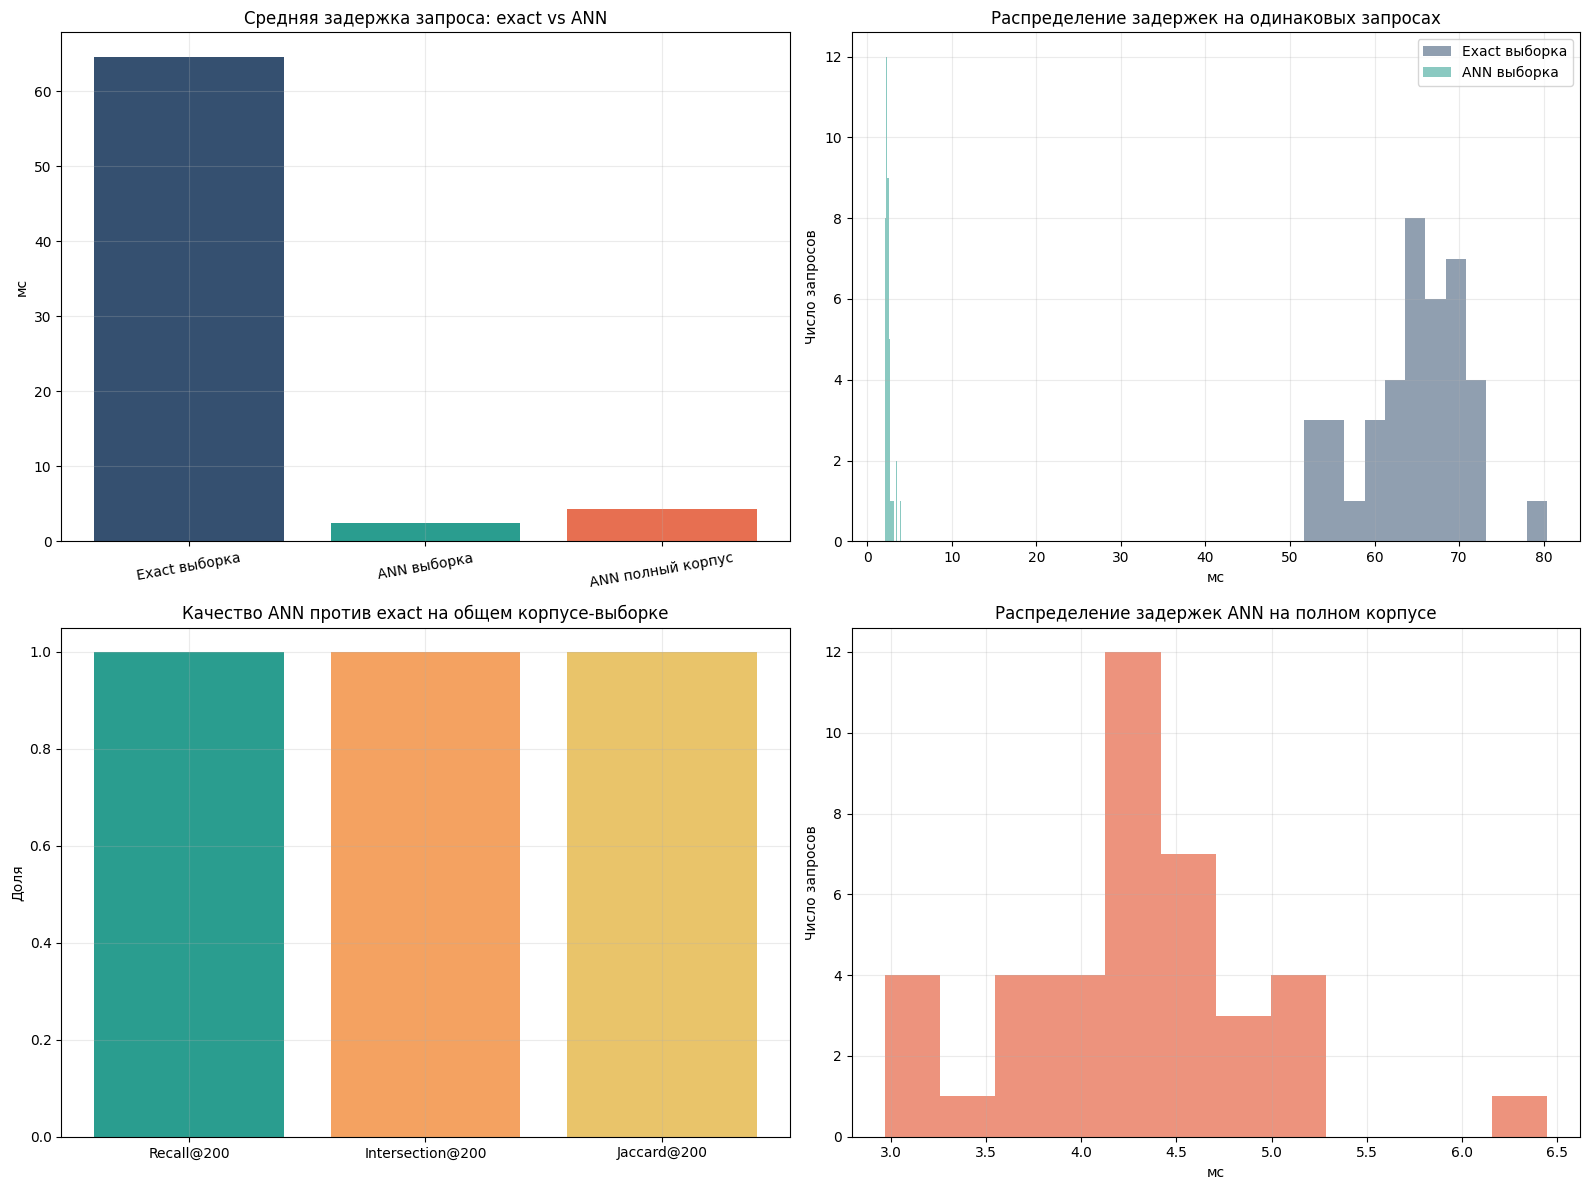

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

speed_compare = pd.DataFrame(
    {
        "Метод": ["Exact выборка", "ANN выборка", "ANN полный корпус"],
        "Среднее время, мс": [
            comparison_summary.iloc[0]["Среднее время запроса, мс"],
            comparison_summary.iloc[1]["Среднее время запроса, мс"],
            comparison_summary.iloc[2]["Среднее время запроса, мс"],
        ],
    }
)
axes[0, 0].bar(
    speed_compare["Метод"],
    speed_compare["Среднее время, мс"],
    color=["#355070", "#2a9d8f", "#e76f51"],
)
axes[0, 0].set_title("Средняя задержка запроса: exact vs ANN")
axes[0, 0].set_ylabel("мс")
axes[0, 0].tick_params(axis="x", rotation=10)

axes[0, 1].hist(
    ann_eval_df["exact_query_ms"],
    bins=12,
    alpha=0.55,
    label="Exact выборка",
    color="#355070",
)
axes[0, 1].hist(
    ann_eval_df["ann_query_ms"],
    bins=12,
    alpha=0.55,
    label="ANN выборка",
    color="#2a9d8f",
)
axes[0, 1].set_title("Распределение задержек на одинаковых запросах")
axes[0, 1].set_xlabel("мс")
axes[0, 1].set_ylabel("Число запросов")
axes[0, 1].legend()

quality_compare = pd.DataFrame(
    {
        "Метрика качества": ["Recall@200", "Intersection@200", "Jaccard@200"],
        "Среднее значение": [
            ann_eval_df["recall_at_200"].mean(),
            ann_eval_df["intersection_at_200"].mean(),
            ann_eval_df["jaccard_at_200"].mean(),
        ],
    }
)
axes[1, 0].bar(
    quality_compare["Метрика качества"],
    quality_compare["Среднее значение"],
    color=["#2a9d8f", "#f4a261", "#e9c46a"],
)
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].set_title("Качество ANN против exact на общем корпусе-выборке")
axes[1, 0].set_ylabel("Доля")

axes[1, 1].hist(
    full_ann_timing_df["query_ms"],
    bins=12,
    color="#e76f51",
    alpha=0.75,
)
axes[1, 1].set_title("Распределение задержек ANN на полном корпусе")
axes[1, 1].set_xlabel("мс")
axes[1, 1].set_ylabel("Число запросов")

plt.tight_layout()
plt.show()


## Финальная функция `get_200_nearest(...)`

Ниже собираем прикладную функцию для поиска top-200 соседей.

Важные оговорки:

- `method='ann'` работает по полному ANN-корпусу и использует основной вариант `with_log1p`;
- `method='exact'` в notebook работает только по baseline-выборке;
- для exact можно выбрать `preprocessing='without_log1p'` или `preprocessing='with_log1p'`;
- функция исключает самого пользователя из выдачи и может вернуть компактный срез интерпретируемых признаков.


In [19]:
def build_neighbors_frame(
    neighbor_idx: np.ndarray,
    distances: np.ndarray,
    local_party_ids: np.ndarray,
    metric: str,
) -> pd.DataFrame:
    result = pd.DataFrame(
        {
            "rank": np.arange(1, len(neighbor_idx) + 1),
            "neighbor_party_rk": local_party_ids[neighbor_idx],
            "distance": distances.astype(float),
        }
    )
    if metric == "cosine":
        result["similarity"] = 1 - result["distance"]
    return result


def get_200_nearest(
    party_rk: str,
    method: str = "ann",
    metric: str = "cosine",
    preprocessing: str = MAIN_PREPROCESSING,
    return_features: bool = False,
) -> Optional[dict]:
    '''
    Вернуть top-200 ближайших пользователей для указанного party_rk.

    Параметры:
    - party_rk: идентификатор пользователя;
    - method: 'ann' или 'exact';
    - metric: метрика поиска;
    - preprocessing: 'without_log1p' или 'with_log1p' для exact;
    - return_features: вернуть компактный интерпретируемый срез признаков.
    '''
    party_rk = str(party_rk)
    started = perf_counter()

    if method == "ann":
        if preprocessing != MAIN_PREPROCESSING:
            print(
                f"Для ANN используется основной препроцессинг '{MAIN_PREPROCESSING}', "
                f"а не '{preprocessing}'."
            )
        if metric != ANN_METRIC:
            print(
                f"Для ANN в notebook построен индекс только для метрики '{ANN_METRIC}'. "
                f"Получено: '{metric}'."
            )
            return None
        if party_rk not in ann_party_index:
            print(f"Пользователь party_rk={party_rk} не найден в ANN-корпусе.")
            return None

        query_pos = int(ann_party_index.get_loc(party_rk))
        neighbor_idx, distances = query_ann(
            ann_full_bundle,
            X_ann[query_pos],
            top_k=TOP_K,
            exclude_index=query_pos,
        )
        neighbors = build_neighbors_frame(neighbor_idx, distances, ann_party_ids, metric)
        backend_name = ann_full_bundle["name"]
        search_universe = len(ann_party_ids)

    elif method == "exact":
        if preprocessing not in sample_matrices:
            print(f"Поддерживаемые варианты preprocessing: {sorted(sample_matrices)}")
            return None
        if metric not in exact_experiments[preprocessing]["models"]:
            print(f"Поддерживаемые exact-метрики: {sorted(exact_experiments[preprocessing]['models'])}")
            return None
        if party_rk not in sample_party_index:
            print(
                "Для exact в этом notebook доступна только baseline-выборка. "
                "Используйте party_rk из выборки или переключитесь на method='ann'."
            )
            return None

        query_pos = int(sample_party_index.get_loc(party_rk))
        model = exact_experiments[preprocessing]["models"][metric]
        distances_raw, indices_raw = model.kneighbors(
            sample_matrices[preprocessing][query_pos : query_pos + 1],
            n_neighbors=TOP_K + 1,
        )
        neighbor_idx, distances = drop_self(
            indices_raw[0],
            distances_raw[0],
            self_idx=query_pos,
            top_k=TOP_K,
        )
        neighbors = build_neighbors_frame(neighbor_idx, distances, sample_party_ids, metric)
        backend_name = "sklearn brute"
        search_universe = len(sample_party_ids)

    else:
        print("Параметр method должен быть равен 'ann' или 'exact'.")
        return None

    elapsed_ms = (perf_counter() - started) * 1_000
    payload = {
        "party_rk": party_rk,
        "method": method,
        "metric": metric,
        "preprocessing": preprocessing if method == "exact" else MAIN_PREPROCESSING,
        "backend": backend_name,
        "search_universe": search_universe,
        "query_time_ms": elapsed_ms,
        "neighbors": neighbors,
    }

    if return_features:
        ids_for_snapshot = [party_rk] + neighbors["neighbor_party_rk"].head(10).tolist()
        payload["feature_snapshot"] = profile_view.loc[ids_for_snapshot].reset_index()

    print(
        f"Запрос выполнен: method={method}, metric={metric}, "
        f"preprocessing={payload['preprocessing']}, backend={backend_name}, "
        f"кандидатов={search_universe:,}, время={elapsed_ms:.2f} мс"
    )
    return payload


## Небольшое демо

Для одного и того же пользователя ниже показываем:

- ANN-результат в основном варианте `with_log1p + cosine`;
- exact-результат без `log1p`;
- exact-результат с `log1p`.

Это позволяет быстро посмотреть, насколько `log1p` меняет соседей даже на уровне одного конкретного кейса.


In [20]:
demo_party_rk = sample_party_ids[example_pos]
print(f"Пользователь для демо: {demo_party_rk}")

ann_result = get_200_nearest(
    demo_party_rk,
    method="ann",
    metric=ANN_METRIC,
    return_features=True,
)
if ann_result is not None:
    print("\nANN / with_log1p / cosine:")
    display(ann_result["neighbors"].head(10))
    display(ann_result["feature_snapshot"])

exact_raw_result = get_200_nearest(
    demo_party_rk,
    method="exact",
    metric="euclidean",
    preprocessing="without_log1p",
    return_features=False,
)
if exact_raw_result is not None:
    print("\nExact / without_log1p / euclidean:")
    display(exact_raw_result["neighbors"].head(10))

exact_log_result = get_200_nearest(
    demo_party_rk,
    method="exact",
    metric="euclidean",
    preprocessing="with_log1p",
    return_features=False,
)
if exact_log_result is not None:
    print("\nExact / with_log1p / euclidean:")
    display(exact_log_result["neighbors"].head(10))


Пользователь для демо: 8cadfd9726f14a0bbf0f636eb3a9a83c4de591ccadbb089fd110d259abdb6dc0
Запрос выполнен: method=ann, metric=cosine, preprocessing=with_log1p, backend=faiss, кандидатов=1,217,027, время=448.94 мс

ANN / with_log1p / cosine:


,rank,neighbor_party_rk,distance,similarity
0,1,de5189272611c8f7147249bbf518bdb6eaccf735c46257fd1843dafb284118a7,0.046668,0.953332
1,2,55426a73502712234c6725e58c8a9ff81e4164cdaf2a96298af37b63366a4a17,0.054103,0.945897
2,3,e7d4950cc2118e5484df4131c14ca652a61ebd416bbf92fbdbde648547df6819,0.058007,0.941993
3,4,c22a2ddb1d634c3750b0d1fc242c731e3d62360d9ee46eeab97afe35fbff65d4,0.061365,0.938635
4,5,4ad67b212141ba10accf8c60d565a750af94de6cb125c7d932c5bc075e147cd9,0.061758,0.938242
5,6,bba58a798dcf246317dade0f5110700b57acf2bbdbbb00ee90a79f0015c98a84,0.064151,0.935849
6,7,30f0d0829cdb8fb8250b5787415f0e2d169a01f46e4f26a4ce883adf0fa6973c,0.064793,0.935207
7,8,f37fd7d8786242c29aea104d7c0a627a273491daf54336de3365071b313f8e07,0.064879,0.935121
8,9,39669e25d5104ede5f90c05a2ae2add73a9c2dc0103531526a8f9271938c301e,0.066600,0.933400
9,10,71299cda9f150ba4ae72710c263cac3a43048004ad84131ed230bf5efedd20cf,0.068633,0.931367


,party_rk,txn_cnt,active_days_cnt,active_weeks_cnt,active_months_cnt,activity_span_days,avg_txn_per_active_day,avg_txn_per_month_active,avg_txn_per_week_active,share_weekend_txn,share_weekday_txn,share_night_txn,share_morning_txn,share_afternoon_txn,share_evening_txn,unique_category_cnt,top_category_txn_share,category_entropy,unique_mcc_cnt,top_mcc_txn_share,mcc_entropy,unique_merchant_cnt,top_merchant_txn_share,merchant_diversity_ratio,category_diversity_ratio,mcc_diversity_ratio,dominant_hour,dominant_weekday,dominant_daypart,days_since_first_txn,days_since_last_txn
0,8cadfd9726f14a0bbf0f636eb3a9a83c4de591ccadbb089fd110d259abdb6dc0,58,21,5,1,25,2.761905,58.0,11.60,0.275862,0.724138,0.086207,0.517241,0.396552,0.000000,11,0.568966,1.628637,19,0.293103,2.510809,31,0.086207,0.534483,0.189655,0.327586,10,Thursday,morning,26.448055,0.476007
1,de5189272611c8f7147249bbf518bdb6eaccf735c46257fd1843dafb284118a7,64,23,5,1,27,2.782609,64.0,12.80,0.218750,0.781250,0.203125,0.781250,0.015625,0.000000,12,0.562500,1.570088,18,0.265625,2.350345,36,0.078125,0.562500,0.187500,0.281250,9,Wednesday,morning,27.720243,0.589664
2,55426a73502712234c6725e58c8a9ff81e4164cdaf2a96298af37b63366a4a17,61,18,5,1,27,3.388889,61.0,12.20,0.131148,0.868852,0.147541,0.852459,0.000000,0.000000,6,0.688525,1.036764,14,0.377049,2.051008,34,0.081967,0.557377,0.098361,0.229508,8,Monday,morning,27.642639,0.630949
3,e7d4950cc2118e5484df4131c14ca652a61ebd416bbf92fbdbde648547df6819,39,15,5,1,27,2.600000,39.0,7.80,0.128205,0.871795,0.076923,0.589744,0.333333,0.000000,11,0.435897,1.797456,15,0.205128,2.343655,28,0.128205,0.717949,0.282051,0.384615,11,Friday,morning,27.517719,0.319780
4,c22a2ddb1d634c3750b0d1fc242c731e3d62360d9ee46eeab97afe35fbff65d4,78,25,5,1,27,3.120000,78.0,15.60,0.397436,0.602564,0.141026,0.628205,0.205128,0.025641,11,0.576923,1.556505,17,0.435897,2.066632,43,0.089744,0.551282,0.141026,0.217949,7,Saturday,morning,27.721794,0.699039
5,4ad67b212141ba10accf8c60d565a750af94de6cb125c7d932c5bc075e147cd9,80,19,5,1,26,4.210526,80.0,16.00,0.237500,0.762500,0.062500,0.762500,0.175000,0.000000,12,0.525000,1.702957,18,0.262500,2.417517,46,0.100000,0.575000,0.150000,0.225000,7,Thursday,morning,27.683380,0.706597
6,bba58a798dcf246317dade0f5110700b57acf2bbdbbb00ee90a79f0015c98a84,70,24,5,1,26,2.916667,70.0,14.00,0.214286,0.785714,0.085714,0.471429,0.414286,0.028571,16,0.385714,2.161275,24,0.171429,2.785661,45,0.128571,0.642857,0.228571,0.342857,11,Thursday,morning,27.845753,1.513704
7,30f0d0829cdb8fb8250b5787415f0e2d169a01f46e4f26a4ce883adf0fa6973c,77,22,5,1,27,3.500000,77.0,15.40,0.233766,0.766234,0.103896,0.649351,0.233766,0.012987,12,0.675325,1.354878,18,0.428571,2.143386,38,0.181818,0.493506,0.155844,0.233766,9,Wednesday,morning,27.560011,0.554410
8,f37fd7d8786242c29aea104d7c0a627a273491daf54336de3365071b313f8e07,77,26,5,1,27,2.961538,77.0,15.40,0.324675,0.675325,0.064935,0.571429,0.363636,0.000000,13,0.584416,1.630647,22,0.415584,2.280017,45,0.077922,0.584416,0.168831,0.285714,6,Saturday,morning,27.677975,0.402072
9,39669e25d5104ede5f90c05a2ae2add73a9c2dc0103531526a8f9271938c301e,47,14,4,1,27,3.357143,47.0,11.75,0.404255,0.595745,0.106383,0.531915,0.340426,0.021277,12,0.595745,1.588411,17,0.234043,2.404450,27,0.127660,0.574468,0.255319,0.361702,8,Sunday,morning,27.484421,0.372025


Запрос выполнен: method=exact, metric=euclidean, preprocessing=without_log1p, backend=sklearn brute, кандидатов=50,000, время=30.37 мс

Exact / without_log1p / euclidean:


,rank,neighbor_party_rk,distance
0,1,f37fd7d8786242c29aea104d7c0a627a273491daf54336de3365071b313f8e07,2.970109
1,2,900c9c7c2e10549339ca66a51c8fbeafb30e2b133c632e03a35f6309eb383961,3.620497
2,3,b0c57d7dcfd0a079f5a7a19e81081b90df3b279889d09e5c22d34c300bd7ce52,3.626690
3,4,fec6c336aca39a45bbec4ef802c0be86fcbbdc102785da2906df4e5315a18260,3.739776
4,5,391567d68e348338dcadcebaf9c69b3f0d9679f65c007fff9020165b621efd13,3.795362
5,6,0ea6e878c58d257998a7a6321bac38fffa432384a8ffffd5eb665ff52e3b3e47,3.804955
6,7,0fbb38e219e616afa03e39c34f2db3a980a575b45c72bd2d9e513d0066d89c31,3.925557
7,8,c999d2c4092b50ce7f8be2dc448be4aa7d19e51aa6686be633e326d7e39bd96f,3.929040
8,9,ccfa73b7cb8a1ff6a8a2546ccdd78ec5981387784486a8a4eec957628f6dcb9c,4.095076
9,10,e9d66eaeb6fc7674bd0100338cd864028d622701eb42edb850b0f75148a9e559,4.156806


Запрос выполнен: method=exact, metric=euclidean, preprocessing=with_log1p, backend=sklearn brute, кандидатов=50,000, время=13.03 мс

Exact / with_log1p / euclidean:


,rank,neighbor_party_rk,distance
0,1,f37fd7d8786242c29aea104d7c0a627a273491daf54336de3365071b313f8e07,2.690908
1,2,900c9c7c2e10549339ca66a51c8fbeafb30e2b133c632e03a35f6309eb383961,3.460064
2,3,b0c57d7dcfd0a079f5a7a19e81081b90df3b279889d09e5c22d34c300bd7ce52,3.481713
3,4,391567d68e348338dcadcebaf9c69b3f0d9679f65c007fff9020165b621efd13,3.543471
4,5,0ea6e878c58d257998a7a6321bac38fffa432384a8ffffd5eb665ff52e3b3e47,3.580221
5,6,fec6c336aca39a45bbec4ef802c0be86fcbbdc102785da2906df4e5315a18260,3.628875
6,7,0fbb38e219e616afa03e39c34f2db3a980a575b45c72bd2d9e513d0066d89c31,3.751118
7,8,ccfa73b7cb8a1ff6a8a2546ccdd78ec5981387784486a8a4eec957628f6dcb9c,3.842683
8,9,c999d2c4092b50ce7f8be2dc448be4aa7d19e51aa6686be633e326d7e39bd96f,3.900823
9,10,e9d66eaeb6fc7674bd0100338cd864028d622701eb42edb850b0f75148a9e559,3.930554


## Итоговые выводы

В этом notebook собран полный сценарий поиска похожих пользователей по агрегированным признакам с явной проверкой влияния `log1p`.

Основные выводы, на которые нужно смотреть по таблицам и графикам выше:

- идентификатор исключён из матрицы, datetime-поля переведены в числовые признаки давности, строковые поля обработаны осмысленно;
- основным scaler остаётся **`RobustScaler`**;
- `log1p` применяется **выборочно**, только к тяжёлым счётчикам и intensity-признакам, а не ко всей матрице подряд;
- сравнение без `log1p` и с `log1p` показывает, насколько сильно трансформация меняет top-200 и форму distance-кривых;
- ошибки метрик относительно `euclidean` считаются не только по overlap списков, но и по `RMSE`/`MAE` нормализованных расстояний;
- если после `log1p` `overlap@200` с `euclidean` растёт, а `RMSE` по distance-кривым падает, это сильный аргумент в пользу `log1p`;
- для прикладного retrieval логично использовать **ANN на варианте `with_log1p + cosine`**, если quality и latency по таблицам выше выглядят разумно.

Практическое правило:

- если нужен быстрый рабочий retrieval на полном корпусе — используем `method='ann'`;
- если нужен честный эталонный baseline и проверка влияния препроцессинга — используем `method='exact'` на выборке.
